In [1]:
import scipy
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import skew
from scipy.stats import kurtosis
from sklearn import linear_model
from itertools import combinations

# import equivariant steerable cnn
import escnn.gspaces
import escnn.nn

import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm import tqdm
# Checking if you have a GPU and CUDA set up -- if not, training will take longer by running on the CPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
# device = 'cpu'
# Set the plotting style
#plt.style.use('seaborn-poster')

In the filter weights training phase, why force beta hyperparameters in the nn.Linear to be positive can pick up characteristics from class A? Is it a special set-up such that only for structured data vs. random? In a binary classification task between gaussian and random, take absbeta to be True or not does not affect the validation accuracy in the training. But it will make both filters have some features instead of force the filter to learn gaussian only?

### Read in an example of the prepared data set

In [2]:
log_example = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/maps_takahashi_cosmo/gaussian_lognormal_z10_z16/lognormal_data_12180_maps_200_by_200pixels_20_by_20deg_zs10_zs16_gnom_projection.npy')[:5000,1,:,:]
grf_example = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/maps_takahashi_cosmo/gaussian_lognormal_z10_z16/gaussian_data_12180_maps_200_by_200pixels_20_by_20deg_zs10_zs16_gnom_projection.npy')[:5000,1,:,:]

### Load training data with a single channel

In [4]:
"""Load snapshots following a spatial random distribution"""
def load_srf(num_snaps, size, srf_data):
    snaps = torch.zeros(num_snaps, 1, size, size, dtype=torch.float32)
    data = torch.tensor(srf_data, dtype=torch.float32)
    # Set the channel to random gaussian distribution
    snaps[:, 0, :, :] = data
    # Split into a train and val set
    num_train = int(0.9 * num_snaps)
    return snaps[:num_train], snaps[num_train:]

"""Shuffle the 2d SRF into a random distribution"""
def shuffle(num_snaps, size, srf_data):
    snaps = np.zeros((num_snaps, size, size))
    for i in range(num_snaps):
        for j in range(size):
            for k in range(size):
                p = np.random.randint(0,size)
                q = np.random.randint(0,size)
                tmp = srf_data[i,j,k]
                snaps[i,j,k] = srf_data[i,p,q]
                snaps[i,p,q] = tmp
    return snaps

In [5]:
train_gaussian, val_gaussian = load_srf(5000, 200, grf_example)
train_log, val_log = load_srf(5000, 200, log_example)

### Load training data with multiple channels

In [4]:
def load_multi_channel_data(num_snaps, srf_data):
    snaps = torch.tensor(srf_data, dtype=torch.float32)
    # Split into a train and val set
    num_train = int(0.9 * num_snaps)
    return snaps[:num_train], snaps[num_train:]

In [5]:
train_gaussian, val_gaussian = load_multi_channel_data(17760, grf_example)
train_log, val_log = load_multi_channel_data(17760, log_example)

In [6]:
"""Assembles tensors of snapshots into torch.DataLoaders to use during training"""
def make_datasets(train_A, train_B, val_A, val_B, batch_size=256):
    train_tensors = torch.cat([train_A, train_B])
    val_tensors = torch.cat([val_A, val_B])
    # Class A is labeled with a 0, class B is labeled with a 1
    train_labels = torch.cat([
        torch.zeros(len(train_A), dtype=torch.int64),
        torch.ones(len(train_B), dtype=torch.int64)
    ])
    val_labels = torch.cat([
        torch.zeros(len(val_A), dtype=torch.int64),
        torch.ones(len(val_B), dtype=torch.int64)
    ])
    
    train_dataset = torch.utils.data.TensorDataset(train_tensors, train_labels)
    val_dataset = torch.utils.data.TensorDataset(val_tensors, val_labels)
    
    pin_memory = True if torch.cuda.is_available() else False
    train_loader = torch.utils.data.DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, pin_memory=pin_memory
    )
    val_loader = torch.utils.data.DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory
    )
    return train_loader, val_loader

## CCNN Architecture

We split the model into two parts and name them as $\textit{CNN based N-point moment map generator}$ and $\textit{moment-map based classifier}$, respectively.

$\textbf{CNN based N-point moment map generator:}$ The generator part of the architecture performs convolution operations recursively in order to produce moment maps $C_{\alpha}^{(N)}$ (of order $N$) which we define as follows:

$$C_{\alpha}^{(1)}(\textbf{x}) = \sum\limits_{\textbf{a},k}w_{\alpha,k}(\textbf{a})S_{k}(\textbf{x}+\textbf{a})$$
$$C_{\alpha}^{(2)}(\textbf{x}) = \frac{1}{2!}\left[\sum\limits^{\{(\textbf{a},k) \neq (\textbf{a}_1,k^{\prime})\}}_{\textbf{a}, \textbf{a}_1, k, k^{\prime}}w_{\alpha,k}(\textbf{a})w_{\alpha,k^{\prime}}(\textbf{a}_1)S_{k}(\textbf{x}+\textbf{a})S_{k^{\prime}}(\textbf{x}+\textbf{a}_1)\right]$$
$$\dots $$
$$C_{\alpha}^{(N)}(\textbf{x}) = \frac{1}{N!}\left[\sum\limits^{\{(\textbf{a},k) \neq\dots\neq (\textbf{a}_N,k_{N})\}}_{\textbf{a},\ldots,\textbf{a}_{N},k,\ldots,k_N}\prod\limits_{j=1}^{N}w_{\alpha,k_{j}}(\textbf{a}_j)S_{k_{j}}(\textbf{x}+\textbf{a}_j)\right] \ . \hspace{3cm} (1)$$
   
Here $w$ is the filter weight exploited in standard CNN filters and $S$ denotes the input map (e.g. a pixelized image of a 2D field). During training, we enforce $w$ to take its absolute value to aid interpretation. The curly brackets above the summation include constraints for the summed variables. Position vectors $\textbf{a}$, $\textbf{a}_1$ $\dots$ $\textbf{a}_N$ of the filter weight run over every pixel within the finite support of the filter. The factorial factor removes repeated counting of the same combination of filter weights and input map pixels. Index $\alpha$ represents different filters while index $k$ goes through different channels. Each filter can have several channels that correspond to those in the input data, e.g.~different tomographic bins of an observable. From the above equations, we see clearly that for $N \geq 2$, $C_{\alpha}^{(N)}(\textbf{x})$ is the weighted summation of all possible pixel configurations within the filter at position $\mathbf{x}$. For $N=1$, $C_{\alpha}^{(1)}$ represents the usual convolution of the input data with the standard CNN filter. In the summation, we strictly exclude zero-lag contributions for any order. The summation over $k$ enables C3NN to measure cross-correlations among different channels of the input data.

One difficulty in computing moment maps is the increasing computational cost along with the order $N$. The cost can be approximated as $\mathcal{O}((KP)^N)$ per input map pixel where $K$ is the number of input data channels and $P$ is the number of pixels in the convolutional filter. To solve this problem, Miles_ccnn_2021 (see their section.~S II) have proved that $C_{\alpha}^{(N)}$ can be calculated using a recursive formula:
$$C_{\alpha}^{(N)}(\textbf{x}) = \frac{1}{N}\sum\limits_{\ell=1}^{N}(-1)^{\ell-1}\left(\sum\limits_{\textbf{a},k}w_{\alpha,k}^{\ell}(\textbf{a})S_{k}^{\ell}(\textbf{x}+\textbf{a})\right)C_{\alpha}^{(N-\ell)}(\textbf{x}) \ , \hspace{3cm} (2)$$
where the power operation is taken on every pixel and we set $C_{\alpha}^{(0)}(\textbf{x})$ to be 0. Through this relation, the computational cost decreases to $\mathcal{O}(N^2KP)$. Instead of direct computation at each order of the moment map, we can now convolve the input only once to produce $C_{\alpha}^{(1)}$. Then $C_{\alpha}^{(2)}$ can be calculated from $C_{\alpha}^{(1)}$. Similarly $C_{\alpha}^{(3)}$ can be calculated from $C_{\alpha}^{(1)}$ and $C_{\alpha}^{(2)}$ and so on via the above equation. This recursive relation holds until we truncate at an order $N$.

$\textbf{Moment-map based classifier:}$ This classifier part of the architecture starts with compressing the $C_{\alpha}^{(N)}$ maps obtained from the generator into scalars $c_{\alpha}^{(N)}$ by taking the spatial average over the maps:
$$c_{\alpha}^{(N)} = \frac{1}{N_{\rm pix}}\sum\limits_{\textbf{x}}C_{\alpha}^{(N)}(\textbf{x}) \ , \hspace{3cm} (3)$$
where $N_{\rm pix}$ is the total number of pixels in the input map $S$. Based on Eqs.(1) and (3), we can explicitly show the relation between $c_{\alpha}^{(N)}$ and the corresponding NPCF both at the discrete filter pixel level and in the continuous limit. As an example, when $N=2$, we have:
$$c_{\alpha}^{(2)} = \frac{1}{N_{\rm pix}}\sum\limits_{\textbf{x}}\frac{1}{2!}\left[\sum\limits^{\{(\textbf{a},k) \neq (\textbf{a}_1,k^{\prime})\}}_{\textbf{a}, \textbf{a}_1, k, k^{\prime}}w_{\alpha,k}(\textbf{a})w_{\alpha,k^{\prime}}(\textbf{a}_1)S_{k}(\textbf{x}+\textbf{a})S_{k^{\prime}}(\textbf{x}+\textbf{a}_1)\right] $$
$$= \frac{1}{2!}\sum\limits^{\{(\textbf{a},k) \neq (\textbf{a}_1,k^{\prime})\}}_{\textbf{a}, \textbf{a}_1, k, k^{\prime}}w_{\alpha,k}(\textbf{a})w_{\alpha,k^{\prime}}(\textbf{a}_1)\left[\frac{1}{N_{\rm pix}}\sum\limits_{\textbf{x}}S_{k}(\textbf{x}+\textbf{a})S_{k^{\prime}}(\textbf{x}+\textbf{a}_1)\right] $$
$$= \frac{1}{2!}\sum\limits^{\{(\textbf{a},k) \neq (\textbf{a}_1,k^{\prime})\}}_{\textbf{a}, \textbf{a}_1, k, k^{\prime}}w_{\alpha,k}(\textbf{a})w_{\alpha,k^{\prime}}(\textbf{a}_1)\hat{\xi}_{kk^{\prime}}(\textbf{a}_1-\textbf{a}) $$
$$= \frac{1}{2!}\sum\limits^{\{(\textbf{a},k) \neq (\textbf{a}+\textbf{r},k^{\prime})\}}_{\textbf{a}, \textbf{r}, k, k^{\prime}}w_{\alpha,k}(\textbf{a})w_{\alpha,k^{\prime}}(\textbf{a}+\textbf{r})\hat{\xi}_{kk^{\prime}}(\textbf{r}) \ , \hspace{3cm} (4)$$
where $\hat{\xi}_{kk^{\prime}}$ is the volume average estimator for auto/cross 2PCFs at a separation $\textbf{r}$ between channels $k$ and $k'$. Note that both $\textbf{a}$ and $\textbf{a}+\textbf{r}$ in the last line should be strictly contained within the filter.

After building all the $c_{\alpha}^{(N)}$ up to a given order $N$, we group them together to form a feature vector $\textbf{c} = \{c_{\alpha}^{(1)}, c_{\alpha}^{(2)}, c_{\alpha}^{(3)},..., c_{\alpha}^{(N)}\}$. Then the vector goes through a batch normalization which applies standard normalization to each batch of the training data to scale all entries of $\mathbf{c}$ to the same order of magnitude for numerical stability during the latter training process. Finally, the model passes it through a logistic classifier for a final probabilistic prediction $\hat{y}$ to differentiate two classes:
$$\hat{y} = \frac{1}{1+{\rm e}^{-\boldsymbol{\beta}\cdot\boldsymbol{c}+\epsilon}} \ , \hspace{3cm} (5)$$
where $\boldsymbol{\beta}$ is a trainable vector composed of coefficients $\beta_{\alpha}^{(N)}$ which have a one-to-one correspondence to $c_{\alpha}^{(N)}$. The other trainable parameter is the bias scalar $\epsilon$. When $-\boldsymbol{\beta}\cdot\boldsymbol{c}+\epsilon=0$, the probabilistic prediction would always be $0.5$ which implies a random classification between two classes. From that naturally the hyperplane $-\boldsymbol{\beta}\cdot\boldsymbol{c}+\epsilon=0$ acts as the decision boundary in the high $N$-dimensional space. C3NN would classify the feature vector $\textbf{c}$ that falls to either side of the decision boundary into a specific class. In other words, if $\hat{y} \in [0,0.5)$, the model would predict the input data to belong to one class. Otherwise, the input data would be considered as the other class.

The filters used in the convolution are constructed in such a way that their weights after training are rotationally symmetric about the central filter pixel, i.e.~weights that have the same distance to the central pixel are identical. We impose this symmetry because the spatially averaged moments $c_{\alpha}^{(N)}$ should be invariant to rotations of the training maps. From the perspective of the cosmological principle, this ensures that our model obeys the isotropy of the Universe. In practice, we implement this in our filters using the equivariant steerable convolutional neural network ($\texttt{ESCNN}$) architecture. The requirement of rotational invariance imposed on the filter naturally decreases the number of free weights to be trained and therefore makes the training procedure more numerically efficient as it needs fewer training data.

In [2]:
bandlimit = 6
gspace = escnn.gspaces.rot2dOnR2(N=-1, maximum_frequency=bandlimit)
#gspace = escnn.gspaces.rot2dOnR2(N=4)

In [3]:
""" Implements the non-linear convolution operation using the recursive formula."""
class NonlinearConv(nn.Module):
    def __init__(self, in_channels, num_filts, filter_size, order):
        super().__init__()
        self.order = order
        self.in_channels = in_channels
        self.num_filts = num_filts
        self.filter_size = filter_size

        """
        # Initialize filter similar as to how Pytorch initializes nn.Conv2d, but all positive
        weight_sample_k = 1.0 / np.sqrt(filter_size**2 * in_channels)
        init_filt = (2 * weight_sample_k * torch.rand(num_filts, in_channels, filter_size, filter_size, dtype=torch.float32))
        self.conv_filt = torch.nn.Parameter(init_filt)
        # Initialize some slices of the filter to be 0
        with torch.no_grad():
            self.conv_filt[:, :, int(self.filter_size/2)-2:int(self.filter_size/2)+3, int(self.filter_size/2)-2:int(self.filter_size/2)+3]=0.0
        """
        
        # Initialize the escnn filter
        #feat_type_in = escnn.nn.FieldType(gspace, self.in_channels*[gspace.irrep(0)])
        #feat_type_out = escnn.nn.FieldType(gspace, self.num_filts*[gspace.irrep(0)])
        #self.conv = escnn.nn.R2Conv(in_type=feat_type_in, out_type=feat_type_out, bias=False, kernel_size=self.filter_size, padding=int((self.filter_size-1)/2.0)) 
        
        feat_type_in = escnn.nn.FieldType(gspace, self.in_channels*[gspace.trivial_repr])
        feat_type_out = escnn.nn.FieldType(gspace, self.num_filts*[gspace.trivial_repr])
        self.conv = escnn.nn.R2Conv(in_type=feat_type_in, out_type=feat_type_out, bias=False, kernel_size=self.filter_size) 
        #with torch.no_grad():
        #    self.conv.weights[:3] = 0.0
        
        
    def forward(self, x):
        # We will work with strictly positive filters for easier interpretation!
        self.abs_filt = self.conv.expand_parameters()[0].abs()
        #abs_filt = self.conv_filt.abs()
        
        # Add a line here to force the central pixels to be 0 (scale cut)
        #self.abs_filt[:, :, int(self.filter.size/2)-2:int(self.filter.size/2)+2, int(self.filter.size/2)-2:int(self.filter.size/2)+2]=0.0
        
        # Convolutions of powers of the input with powers of the absolute valued filter
        conv_powers = [F.conv2d(x ** k, self.abs_filt ** k, stride=1, padding=int((self.filter_size-1)/2.0)) for k in range(1, self.order + 1)]
        #conv_powers = [F.conv2d(x ** k, abs_filt ** k, stride=1, padding=int((self.filter_size-1)/2.0)) for k in range(1, self.order + 1)]

        # C_0 is defined to be one everywhere
        corrs = [torch.ones_like(conv_powers[0])]

        # Compute each order of C_n recursively
        for n in range(1, self.order + 1):
            Cn = torch.zeros_like(conv_powers[0])
            for k in range(n):
                Cn += (-1) ** k * conv_powers[k] * corrs[n - k - 1]
            Cn /= n
            corrs.append(Cn)

        # Stack correlator maps along the channel dimension, dropping the zeroth order (C_0)
        # Here the channel dimension refers to the number of channels
        return torch.cat(corrs[1:], dim=-3)

In [4]:
""" Return the same input """
class Identity(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return x

In [5]:
""" Does a simple average over the last two dimensions of the input."""
class Mean2d(nn.Module):
    def __init__(self):
        super().__init__()
        
    def forward(self, x):
        return x.mean((-2, -1))
        #return torch.abs(x.mean((-2, -1)))

In [6]:
class probability_concatenation(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return torch.cat((x, torch.zeros_like(x)), dim=-1)

In [7]:
""" The full CCNN is Input -> NonlinearConv -> Spatial Avg -> BatchNorm -> Logistic. The way it is constructed
    here assumes a binary classification task, but this can be extended to the multiclass case."""
class CCNN(nn.Module):
    def __init__(self, in_channels, num_filts, filter_size, order, absbeta=False, slice=False, pool=False):
        super().__init__()
        self.in_channels = in_channels
        self.num_filts = num_filts
        self.filter_size = filter_size
        self.order = order
        self.absbeta = absbeta
        
        """
        self.slice = slice
        self.pool = pool
        self.symslice = SymSlice()
        self.identity = Identity()
        self.sympool = SymPool()

        if self.slice:
            self.symslice = SymSlice()
        else:
            self.symslice = Identity()
        
        self.corr_conv = NonlinearConv(in_channels, num_filts, filter_size, order)
        
        if self.pool:
            self.sympool = SymPool()
        else:
            self.sympool = Identity()
        
        self.spatial_mean = Mean2d()
        self.bn = nn.BatchNorm1d(num_filts * order, affine=True, eps=3.185289e-35, dtype=torch.float32)
        self.logistic_fc = nn.Linear(num_filts * order, 1, dtype=torch.float32)
        self.concat = probability_concatenation()
        """

        
        # the model architecture with escnn
        self.corr_conv = NonlinearConv(self.in_channels, self.num_filts, self.filter_size, self.order)
        self.spatial_mean = Mean2d()
        self.bn = nn.BatchNorm1d(num_filts * order, affine=True, eps=3.185289e-35, dtype=torch.float32)
        self.logistic_fc = nn.Linear(num_filts * order, 1, dtype=torch.float32)
        # If absbeta is set, force the beta_alpha^(n) parameters to be strictly positive
        # The effect of this is that the model can only pick up features which "give evidence for" class A
        self.concat = probability_concatenation()
        
    
    
    def forward(self, x, chop=False):    
        
        
        x = self.corr_conv(x)
        x = self.spatial_mean(x)
        if chop == False:
            x = self.bn(x)
            x = self.logistic_fc(x)
            if self.absbeta:
                self.logistic_fc.weight.data.abs_()
            # Treat the output as if logit 0 has the value predicted by model, logit 1 has logit 0
            x = self.concat(x)

        return x

In [13]:
#=== 1) Create SRF DataLoaders ===#

train_loader, val_loader = make_datasets(train_gaussian, train_log, val_gaussian, val_log)

In [17]:
#=== 2) Set up some things for training ===#
# Number of times the model will see the full dataset
epochs = 5
# The initial learning rate -- an important hyperparameter
lr = 0.505631 
#lr = 0.5
# The strength of the regularization loss -- we can make this very strong in these easy toy examples
gamma = 0.030383
#gamma = 5e-4
# The number of input channels 
in_channels = 1
# The number of filters to learn in our model
num_filts = 1
# The spatial length of the filters
filter_size = 11
# The highest order of correlation measured
order = 4
# Make our model -- for simplicity, let's train a two-filter model
ccnn = CCNN(in_channels=in_channels, num_filts=num_filts, filter_size=filter_size, order=order, absbeta=False).to(device=device)

# The optimizer
#optimizer = torch.optim.Adam(ccnn.parameters(), lr=lr)
optimizer = torch.optim.RMSprop(ccnn.parameters(), lr=lr)
#optimizer = torch.optim.SGD(ccnn.parameters(), lr=lr)

# A learning schedule which will ramp down the learning rate as we train
lr_scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, 0.067646)
# Our loss function
criterion = nn.CrossEntropyLoss()

To further develop the interpretability, we adopt a two-round training strategy: In the first round, we train the whole C3NN. In this case, we use the binary cross-entropy as the loss function with an extra L1 regularization term on the filter weights:
$$L_{\rm 1st}(y,\hat{y}) = -y{\rm log}\hat{y} - (1-y){\rm log}(1-\hat{y}) + \gamma\sum\limits_{\alpha,k, \textbf{a}}w_{\alpha,k}(\textbf{a}) \ ,\hspace{3cm} \ ,$$
where $\gamma$ is the regularization strength. This regularization term helps to turn off unnecessary pixels which aid our later interpretation of the filter weights. The resulting C3NN model can be directly used to perform binary classification tasks. In the second round, we freeze the filter weights from the previous round and use the moment map generator to produce moment maps. We then use those maps to re-train $\beta_{\alpha}^{(N)}$ coefficients and $\mathbf{\epsilon}$ in Eq.(5). It is important to note that the value of $\beta_{\alpha}^{(N)}$ indicates the relative importance of $c_{\alpha}^{(N)}$ in its contribution to the classification, e.g. from Eq.~\ref{eq:logistic_prediction} when $\beta_{\alpha}^{(N)}=0$, its corresponding $c_{\alpha}^{(N)}$ would be irrelevant in C3NN's decision making. Based on this property, we use a different L1 regularization term in the binary cross-entropy loss during the second round of training:
$$L_{\rm 2nd}(y, \hat{y}) = -y{\rm log}\hat{y} - (1-y){\rm log}(1-\hat{y}) + \lambda\sum\limits_{\alpha,n}|\beta^{(n)}_{\alpha}| \ ,\hspace{3cm} \ ,$$
where $\lambda$ is the regularization strength. We train the $\beta_{\alpha}^{(N)}$ coefficients iteratively with gradually decreasing $\lambda$ values. This is a process of feature selection using the so-called regularization path analysis \citep{least_angle_regression_2004, tang2014feature}. Initially, when $\lambda$ is large, all $\beta_{\alpha}^{(N)}$ values are close to 0 in order to minimize $L_{\rm 2nd}$ and therefore the model does not possess any classification power. After $\lambda$ decreases to a certain value, the most important feature represented by a given $\beta_{\alpha}^{(N)}$ would be activated since at this stage the increase in the loss from $\lambda\sum\limits_{\alpha,n}|\beta^{(n)}_{\alpha}|$ would be over-compensated by the decrease from $-y{\rm log}\hat{y} - (1-y){\rm log}(1-\hat{y})$ and thus minimize the total loss. As $\beta_{\alpha}^{(N)}$ is coupled to $c_{\alpha}^{(N)}$, the sequence of the activation of $\beta_{\alpha}^{(N)}$ can provide us insights into the relative importance of different moments.

Once we find the sequence of the $\beta_{\alpha}^{(N)}$ activation, we can check the filter weights that are trained during the first round. For each corresponding moment $c_{\alpha}^{(N)}$ measured by a specific filter, we can quantify the relative importance of a particular NPCF configuration. The method is demonstrated in Figure \ref{fig:filter_analysis_demonstration}. As an aside, we note here that the smallest configuration of the correlation function at a given order is determined by the pixel resolution of the input map. This method implies that we can not only infer a rank of moments based on their relative importance in classification but also a rank of correlation function configurations based on the relative weights within each moment.

In [14]:
"""Performs one training epoch, feeding an entire DataLoader through a model,
   performing gradient descent and keeping track of the average loss and accuracy."""
def train(model, optimizer, criterion, loader, gamma, device='cuda'):
    model.train()
    loss_total = 0.0
    accuracy_total = 0.0
    for inputs, labels in loader:
        # Zero out gradients from the previous iteration
        optimizer.zero_grad()
        
        # Send the inputs and outputs to the GPU (if using one)
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Feed the input through the network, measure the loss
        pred = model(inputs)
        loss = criterion(pred, labels)
        
        # Add our regularization loss on the filter weights
        #l1_loss = model.corr_conv.conv_filt.norm(1)
        l1_loss = model.corr_conv.conv.expand_parameters()[0].norm(1)
        #l1_loss = model.corr_conv.abs_filt.norm(1)
        loss += gamma * l1_loss

        # Backprop gradients
        loss.backward()

        """
        # fix the gradient of the pixels within the scale cut
        for i, param in enumerate(model.parameters()):
            if i == 0:
                param.grad[:3] = torch.zeros_like(param.grad[:1])
                #param.grad[:,:,int(model.filter_size/2)-2:int(model.filter_size/2)+3, int(model.filter_size/2)-2:int(model.filter_size/2)+3] = torch.zeros_like(param.grad[:,:,int(model.filter_size/2)-2:int(model.filter_size/2)+3, int(model.filter_size/2)-2:int(model.filter_size/2)+3])
        """
        
        # Update model parameters by one gradient descent step
        optimizer.step()

        # Do some bookkeeping of the current loss and accuracy
        loss_total += loss.item()
        pred_classes = pred.argmax(dim=1).cpu()
        labels = labels.cpu()
        accuracy_total += torch.count_nonzero(pred_classes == labels).item() / len(pred_classes)

    avg_loss = loss_total / len(loader)
    avg_acc = accuracy_total / len(loader)
    return avg_loss, avg_acc

In [15]:
"""Performs one validation epoch, feeding an entire DataLoader through a model, and
   calculating the average loss and accuracy."""
def val(model, criterion, loader, gamma, device='cuda'):
    model.eval()
    loss_total = 0.0
    accuracy_total = 0.0
    
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            pred = model(inputs)
            loss = criterion(pred, labels)

            #l1_loss = model.corr_conv.conv_filt.norm(1)
            l1_loss = model.corr_conv.conv.expand_parameters()[0].norm(1)
            #l1_loss = model.corr_conv.abs_filt.norm(1)
            loss += gamma * l1_loss

            loss_total += loss.item()
            pred_classes = pred.argmax(dim=1).cpu()
            labels = labels.cpu()
            accuracy_total += torch.count_nonzero(pred_classes == labels).item() / len(pred_classes)
            
    avg_loss = loss_total / len(loader)
    avg_acc = accuracy_total / len(loader)
    return avg_loss, avg_acc

In [18]:
#=== 3) The main training loop! ===#
# Some lists to keep track of losses and accuracies
train_losses, val_losses = [], []
train_accs, val_accs = [], []
for epoch in tqdm(range(epochs), desc="Epoch"):
    # Train
    train_loss, train_acc = train(
        ccnn, optimizer, criterion, train_loader,
        gamma=gamma, device=device
    )
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    # Val
    val_loss, val_acc = val(
        ccnn, criterion, val_loader,
        gamma=gamma, device=device
    )
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    
    # Step the learning rate schedule
    lr_scheduler.step()

Epoch: 100%|██████████████████████████████████████████████████████████| 5/5 [01:21<00:00, 16.32s/it]


In [55]:
torch.save(ccnn, 'trained_model/ccnn_gaussian_lognormal_classification_1_filter_t17_cosmo_zs16_4deg_120pixels_order4_hypertuned.pt')

In [13]:
list(ccnn.modules())

[CCNN(
   (corr_conv): NonlinearConv(
     (conv): R2Conv([SO(2)_on_R2[(None, -1)]: {irrep_0 (x1)}(1)], [SO(2)_on_R2[(None, -1)]: {irrep_0 (x1)}(1)], kernel_size=31, stride=1, padding=15, bias=False)
   )
   (spatial_mean): Mean2d()
   (bn): BatchNorm1d(4, eps=3.185289e-35, momentum=0.1, affine=True, track_running_stats=True)
   (logistic_fc): Linear(in_features=4, out_features=1, bias=True)
   (concat): probability_concatenation()
 ),
 NonlinearConv(
   (conv): R2Conv([SO(2)_on_R2[(None, -1)]: {irrep_0 (x1)}(1)], [SO(2)_on_R2[(None, -1)]: {irrep_0 (x1)}(1)], kernel_size=31, stride=1, padding=15, bias=False)
 ),
 R2Conv([SO(2)_on_R2[(None, -1)]: {irrep_0 (x1)}(1)], [SO(2)_on_R2[(None, -1)]: {irrep_0 (x1)}(1)], kernel_size=31, stride=1, padding=15, bias=False),
 BlocksBasisExpansion(
   (block_expansion_('irrep_0', 'irrep_0')): SingleBlockBasisExpansion()
 ),
 SingleBlockBasisExpansion(),
 Mean2d(),
 BatchNorm1d(4, eps=3.185289e-35, momentum=0.1, affine=True, track_running_stats=True),


In [19]:
#=== Steps (1) + (2): Preprocessing ===#

#=== 1) Precompute all of the c_α^(n) ===#

# Make a model which is only the "front half" of the CCNN, stopping before applying the nn.Linear

chopped_ccnn_modules = []
for module in list(ccnn.modules())[1:5]:
#for module in list(ccnn.modules()):
    #if type(module) is not nn.Linear:
    #if (type(module) != nn.Linear) & (type(module) != nn.BatchNorm1d):
    #    chopped_ccnn_modules.append(module)
    chopped_ccnn_modules.append(module)
chopped_ccnn = nn.Sequential(*chopped_ccnn_modules)

"""
chopped_ccnn_modules_l = []
for module in list(ccnn_filter_l.modules())[1:5]:
    #if type(module) is not nn.Linear:
    #if (type(module) != nn.Linear) & (type(module) != nn.BatchNorm1d):
        #chopped_ccnn_modules.append(module)
    chopped_ccnn_modules_l.append(module)
chopped_ccnn_l = nn.Sequential(*chopped_ccnn_modules_l)

chopped_ccnn_modules_s = []
for module in list(ccnn_filter_s.modules())[1:5]:
    #if type(module) is not nn.Linear:
    #if (type(module) != nn.Linear) & (type(module) != nn.BatchNorm1d):
        #chopped_ccnn_modules.append(module)
    chopped_ccnn_modules_s.append(module)
chopped_ccnn_s = nn.Sequential(*chopped_ccnn_modules_s)
"""

'\nchopped_ccnn_modules_l = []\nfor module in list(ccnn_filter_l.modules())[1:5]:\n    #if type(module) is not nn.Linear:\n    #if (type(module) != nn.Linear) & (type(module) != nn.BatchNorm1d):\n        #chopped_ccnn_modules.append(module)\n    chopped_ccnn_modules_l.append(module)\nchopped_ccnn_l = nn.Sequential(*chopped_ccnn_modules_l)\n\nchopped_ccnn_modules_s = []\nfor module in list(ccnn_filter_s.modules())[1:5]:\n    #if type(module) is not nn.Linear:\n    #if (type(module) != nn.Linear) & (type(module) != nn.BatchNorm1d):\n        #chopped_ccnn_modules.append(module)\n    chopped_ccnn_modules_s.append(module)\nchopped_ccnn_s = nn.Sequential(*chopped_ccnn_modules_s)\n'

In [17]:
# Pass all of the data through this model to obtain the c_α^(n) [corr_feats]
train_cαs, train_labels = [], []
train_cαs_A, train_cαs_B = [], []
val_cαs, val_labels = [], []
val_cαs_A, val_cαs_B = [], []
with torch.no_grad():
    for inputs, labels in train_loader:
        train_mask_A = torch.reshape((labels == 0).nonzero(), (-1,))
        train_mask_B = torch.reshape((labels == 1).nonzero(), (-1,))
        #train_inputs_A = inputs[train_mask_A]
        #train_inputs_B = inputs[train_mask_B]
        
        #train_inputs_A = train_inputs_A.to(device=device)
        #train_inputs_B = train_inputs_B.to(device=device)
        inputs = inputs.to(device=device)
        
        #cα = chopped_ccnn(inputs).cpu()
        cα = ccnn(inputs, chop=True).cpu()
        cα_A = cα[train_mask_A]
        cα_B = cα[train_mask_B]
        train_cαs.append(cα)
        train_cαs_A.append(cα_A)
        train_cαs_B.append(cα_B)
        train_labels.append(labels)
    for inputs, labels in val_loader:
        val_mask_A = torch.reshape((labels == 0).nonzero(), (-1,))
        val_mask_B = torch.reshape((labels == 1).nonzero(), (-1,))
        
        inputs = inputs.to(device=device)
        #cα = chopped_ccnn(inputs).cpu()
        cα = ccnn(inputs, chop=True).cpu()
        cα_A = cα[val_mask_A]
        cα_B = cα[val_mask_B]
        val_cαs.append(cα)
        val_cαs_A.append(cα_A)
        val_cαs_B.append(cα_B)
        val_labels.append(labels)

train_cαs = torch.cat(train_cαs).numpy()
train_cαs_A = torch.cat(train_cαs_A).numpy()
train_cαs_B = torch.cat(train_cαs_B).numpy()
train_labels = torch.cat(train_labels).numpy()

val_cαs = torch.cat(val_cαs).numpy()
val_cαs_A = torch.cat(val_cαs_A).numpy()
val_cαs_B = torch.cat(val_cαs_B).numpy()
val_labels = torch.cat(val_labels).numpy()

In [18]:
#=== 2) Normalize all c_α^{(n)} to zero mean and unit variance ===#
train_mean = train_cαs.mean(axis=0, keepdims=True, dtype=np.float64)
train_std = train_cαs.std(axis=0, keepdims=True, ddof=1, dtype=np.float64)
val_mean = val_cαs.mean(axis=0, keepdims=True, dtype=np.float64)
val_std = val_cαs.std(axis=0, keepdims=True, ddof=1, dtype=np.float64)

train_cαs_norm = (train_cαs - train_mean) / (train_std)
val_cαs_norm = (val_cαs - val_mean) / (val_std) 
train_cαs_A_norm = (train_cαs_A - train_mean) / (train_std)
train_cαs_B_norm = (train_cαs_B - train_mean) / (train_std)

In [19]:
#=== 3) Set up a logistic regression problem using sklearn ===#
logistic_clf = sklearn.linear_model.LogisticRegression(
    penalty="l1", solver='saga', warm_start=True, tol=1e-4,
    fit_intercept=True, max_iter=int(1e4)
)
# A list of inv_λs to train the model at.
inv_λs = np.logspace(-5, 1, num=2000)
# orders of correlator estimator
corr_order = 4
num_filts = 1
# Arrays/Lists to keep track of β_α^(n) and accuracies 
#β_αs = np.empty((len(inv_λs), corr_order * num_filts))
β_αs = np.zeros((len(inv_λs), corr_order * num_filts))
β_αs_intercept = np.zeros(len(inv_λs))
train_accs = np.empty(len(inv_λs))
val_accs = np.empty(len(inv_λs))
mask = np.ones(corr_order * num_filts, dtype=bool)
#mask[0] = 0
#mask[3] = 0
#mask[1] = 0
#mask[2] = 0
#mask[5] = 0

train_cαs_norm_masked = (train_cαs_norm[None,:]*mask)[0]
val_cαs_norm_masked = (val_cαs_norm[None,:]*mask)[0]

# Do the whole series of regressions!
for i, inv_λ in tqdm(enumerate(inv_λs), total=len(inv_λs)):
    # Set the regularization strength -- what sklearn calls C we call 1/λ
    logistic_clf.set_params(C=inv_λ)
    # Perform the regression
    logistic_clf.fit(train_cαs_norm_masked, train_labels)
    
    # Fix the β^3_1 coefficient after other β coefficients become non-zero
    #if logistic_clf.coef_.ravel()[0] != 0:
    #    logistic_clf.coef_.ravel()[0] = β_fix
    
    # Record the current coefficients β_α^(n)
    β_αs[i] = logistic_clf.coef_.ravel().copy()
    β_αs_intercept[i] = logistic_clf.intercept_.copy()
    # Record the current accuracies
    train_accs[i] = logistic_clf.score(train_cαs_norm_masked, train_labels)
    val_accs[i] = logistic_clf.score(val_cαs_norm_masked, val_labels)

100%|███████████████████████████████████████████████████████████████| 2000/2000 [01:50<00:00, 18.17it/s]


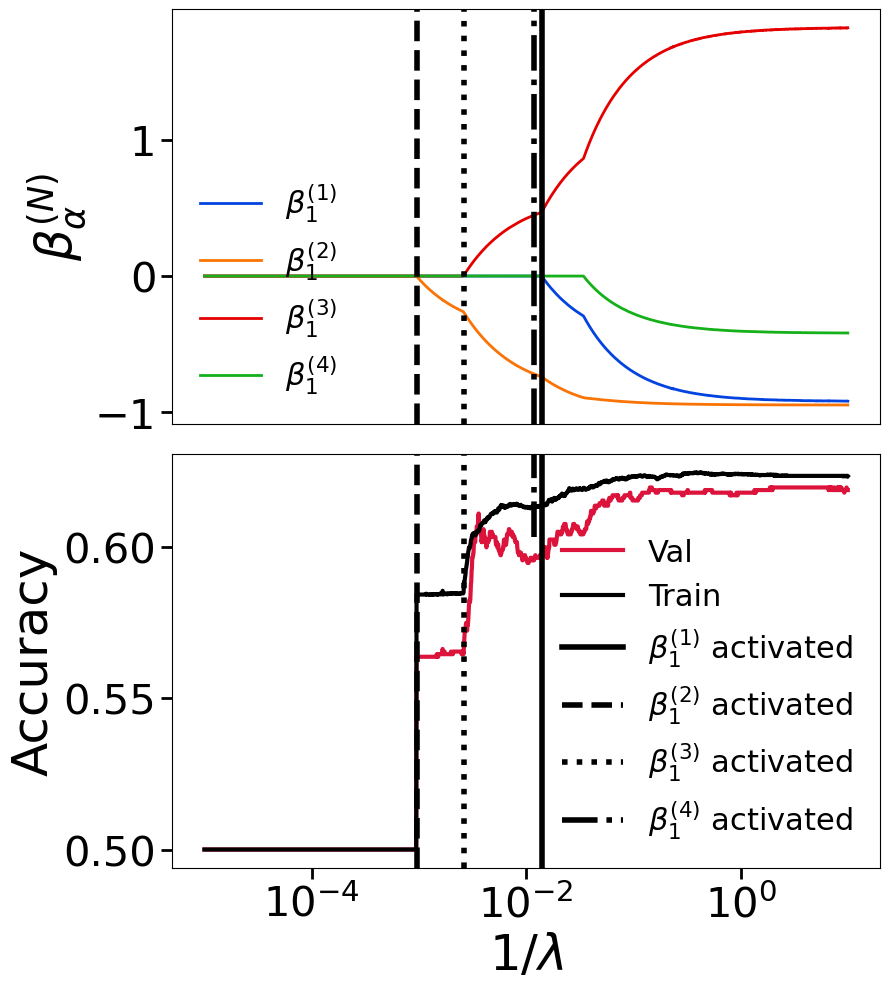

In [24]:
fig, axs = plt.subplots(2, 1, figsize=(9, 10))
β_ax, acc_ax = axs[0], axs[1]

β_ax.set_xscale('log')
β_ax.set_ylabel(r"$\beta_\alpha^{(N)}$", fontsize=36)
β_ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
β_ax.tick_params(axis='y', labelsize=30, length=8.0, width=2.0)
acc_ax.set_xscale('log')
acc_ax.set_ylabel("Accuracy", fontsize=36)
acc_ax.set_xlabel(r"$1/\lambda$", fontsize=36)
acc_ax.tick_params(axis='x', which='major', labelsize=30, length=8.0, width=2.0)
acc_ax.tick_params(axis='x', which='minor', length=4.0, width=2.0)
acc_ax.tick_params(axis='y', labelsize=30, length=8.0, width=2.0)

# Colors of each β trajectory
colors = [
    #["xkcd:deep purple", "xkcd:royal purple", "xkcd:violet", "xkcd:light purple", "xkcd:pale purple"],
    #["xkcd:deep purple", "xkcd:royal purple", "xkcd:violet", "xkcd:light purple"],
    #["xkcd:burnt umber", "xkcd:dark orange", "xkcd:orange", "xkcd:pale orange"],
    ["xkcd:blue", "xkcd:orange", "xkcd:red", "xkcd:green"],
    #["xkcd:pale green", "xkcd:sea green", "xkcd:green", "xkcd:olive green"],
    #["xkcd:grass green", "xkcd:puke green", "xkcd:dark orange", "xkcd:orange", "xkcd:pale orange", "xkcd:red orange"],
    #["xkcd:grass green", "xkcd:puke green", "xkcd:dark orange", "xkcd:orange", "xkcd:pale orange", "xkcd:red orange", "xkcd:fuchsia"],
    #["xkcd:grass green", "xkcd:puke green", "xkcd:dark orange", "xkcd:orange", "xkcd:pale orange", "xkcd:red orange", "xkcd:fuchsia", "xkcd:black"]
]


for ifilt in range(num_filts):
    for iorder in range(corr_order):
    #for iorder in range(3):
        # Index into β_αs
        iβ = iorder * num_filts + ifilt
        color = colors[ifilt][iorder]
        label = r"$\beta_" + str(ifilt+1) + "^{(" + str(iorder+1) + ")}$"
        # There's an overall sign difference in how we define β_α in our CCNN
        # versus sklearn's LogisticRegression, so plot -β_α^(n)
        β_ax.plot(inv_λs, -β_αs[:, iβ], color=color, lw=2, label=label)

β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 0])[0][0]], linestyle='-', color='black', lw=4.0)
β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 1])[0][0]], linestyle='--', color='black', lw=4.0)
β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 2])[0][0]], linestyle='dotted', color='black', lw=4.0)
β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 3])[0][0]], linestyle='dashdot', color='black', lw=4.0)

#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 0])[0][0]], linestyle='--', color='xkcd:grass green', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 1])[0][0]], linestyle='--', color='xkcd:puke green', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 2])[0][0]], linestyle='--', color='xkcd:dark orange', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 3])[0][0]], linestyle='--', color='xkcd:orange', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 4])[0][0]], linestyle='--', color='xkcd:pale orange', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 5])[0][0]], linestyle='--', color='xkcd:red orange', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 6])[0][0]], linestyle='--', color='xkcd:fuchsia', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 7])[0][0]], linestyle='--', color='xkcd:black', lw=3.0)

β_ax.legend(fontsize=22, frameon=False, loc='lower left')
#β_ax.legend(fontsize=20, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))    

# Plot the accuracies
acc_ax.plot(inv_λs, val_accs, lw=3, color='crimson', label="Val")
acc_ax.plot(inv_λs, train_accs, lw=3, color='black', label="Train")

acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 0])[0][0]], linestyle='-', color='black', lw=4.0, label=r'$\beta_{1}^{(1)}$ '+'activated')
acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 1])[0][0]], linestyle='--', color='black', lw=4.0, label=r'$\beta_{1}^{(2)}$ '+'activated')
acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 2])[0][0]], linestyle='dotted', color='black', lw=4.0, label=r'$\beta_{1}^{(3)}$ '+'activated')
acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 3])[0][0]], ymin=0.80, linestyle='dashdot', color='black', lw=4.0, label=r'$\beta_{1}^{(4)}$ '+'activated')

#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 0])[0][0]], linestyle='--', color='xkcd:grass green', lw=3.0, label=r'$\beta_{1}^{(1)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 1])[0][0]], linestyle='--', color='xkcd:puke green', lw=3.0, label=r'$\beta_{1}^{(2)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 2])[0][0]], linestyle='--', color='xkcd:dark orange', lw=3.0, label=r'$\beta_{1}^{(3)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 3])[0][0]], linestyle='--', color='xkcd:orange', lw=3.0, label=r'$\beta_{1}^{(4)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 4])[0][0]], linestyle='--', color='xkcd:pale orange', lw=3.0, label=r'$\beta_{1}^{(5)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 5])[0][0]], linestyle='--', color='xkcd:red orange', lw=3.0, label=r'$\beta_{1}^{(6)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 6])[0][0]], linestyle='--', color='xkcd:fuchsia', lw=3.0, label=r'$\beta_{1}^{(7)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 7])[0][0]], linestyle='--', color='xkcd:black', lw=3.0, label=r'$\beta_{1}^{(8)}$ '+'activated')

acc_ax.legend(fontsize=22, frameon=False, loc='lower right')
#acc_ax.legend(fontsize=20, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))    
fig.tight_layout()

plt.show()
#plt.savefig('paper_plot/grf_lognormal_regularization_path_up_to_c4.pdf', format='pdf', dpi=300, bbox_inches='tight')

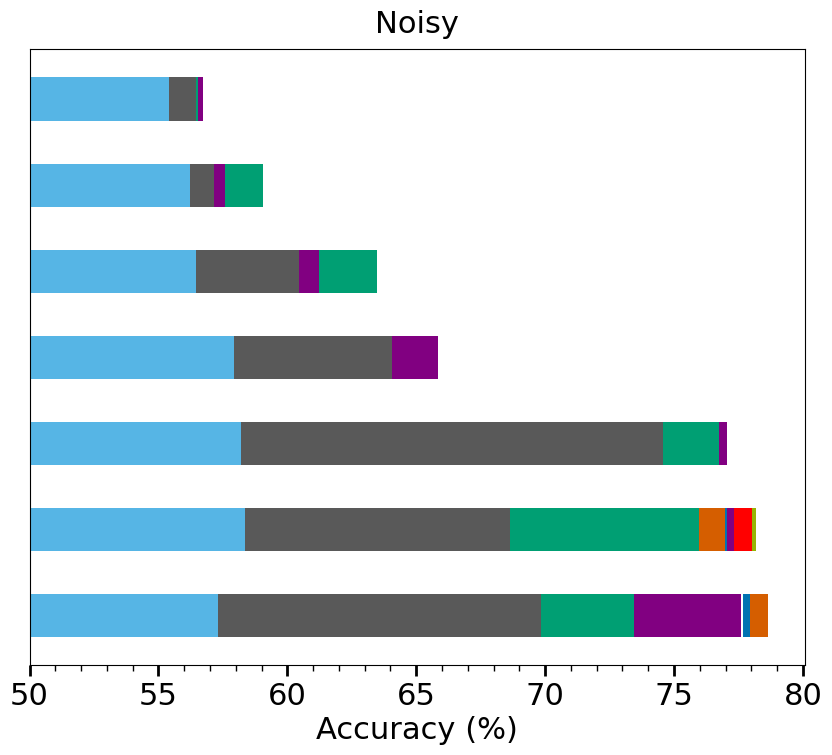

In [52]:
plt.figure(figsize=(10,8))
test_group = ['no smoothing and \ntuned filter size,\ncorrelation order', 'no smoothing and \ntuned correlation order', 'no smoothing', r'$10^{\prime}$ '+'smoothing', r'$20^{\prime}$ '+'smoothing', r'$30^{\prime}$ '+'smoothing', r'$40^{\prime}$ '+'smoothing']
start = np.array([50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0])
c2 = np.array([7.33, 8.36, 8.19, 7.93, 6.47, 6.21, 5.43]) 
c3 = np.array([12.5, 10.26, 16.38, 6.12, 3.97, 0.95, 1.03])

test_group1 = ['no smoothing and \ntuned filter size,\ncorrelation order', 'no smoothing', r'$10^{\prime}$ '+'smoothing', r'$40^{\prime}$ '+'smoothing']
start1 = np.array([50.0, 50.0, 50.0, 50.0])
c1_1 = np.array([3.62, 2.16, 0, 0.09])
c2_1 = np.array([7.33, 8.19, 7.93, 5.43])
c3_1 = np.array([12.5, 16.38, 6.12, 1.03])
c4_1 = np.array([4.14, 0.34, 1.81, 0.17])

test_group2 = [r'$20^{\prime}$ '+'smoothing', r'$30^{\prime}$ '+'smoothing']
start2 = np.array([50.0, 50.0])
c1_2 = np.array([2.24, 1.47])
c2_2 = np.array([6.47, 6.21])
c3_2 = np.array([3.97, 0.95])
c4_2 = np.array([0.78, 0.43])

test_group3 = ['no smoothing and \ntuned filter size,\ncorrelation order']
start3 = np.array([50])
c1_3 = np.array([3.62])
c2_3 = np.array([7.33])
c3_3 = np.array([12.59])
c4_3 = np.array([4.14])
c5_3 = np.array([0.26])
c6_3 = np.array([0.69])

test_group4 = ['no smoothing and \ntuned correlation order']
start4 = np.array([50])
c1_4 = np.array([7.33])
c2_4 = np.array([8.36])
c3_4 = np.array([10.26])
c4_4 = np.array([0.26])
c5_4 = np.array([0.09])
c6_4 = np.array([1.03])
c7_4 = np.array([0.69])
c8_4 = np.array([0.17])

height = np.array([0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5])
height1 = np.array([0.5, 0.5, 0.5, 0.5])
height2 = np.array([0.5, 0.5])
height3 = np.array([0.5])
height4 = np.array([0.5])

b1 = plt.barh(test_group, c2, left=start, color="#56b5e5", height=height)
b2 = plt.barh(test_group, c3, left=c2+start, color="#595959", height=height)
b3_1 = plt.barh(test_group1, c1_1, left=c2_1+c3_1+start1, color="#009f73", height=height1)
b4_1 = plt.barh(test_group1, c4_1, left=c2_1+c3_1+c1_1+start1, color='#810081', height=height1)
b3_2 = plt.barh(test_group2, c4_2, left=c2_2+c3_2+start2, color='#810081', height=height2)
b4_2 = plt.barh(test_group2, c1_2, left=c2_2+c3_2+c4_2+start2, color='#009f73', height=height2)
b5_3 = plt.barh(test_group3, c5_3, left=c1_3+c2_3+c3_3+c4_3+start3, color='#0072b1', height=height3) # 
b6_3 = plt.barh(test_group3, c6_3, left=c1_3+c2_3+c3_3+c4_3+c5_3+start3, color='#d55e00', height=height3)
b7_4 = plt.barh(test_group4, c1_4, left=c2_4+c3_4+start4, color="#009f73", height=height4)
b8_4 = plt.barh(test_group4, c6_4, left=c1_4+c2_4+c3_4+start4, color='#d55e00', height=height4)
b9_4 = plt.barh(test_group4, c5_4, left=c6_4+c1_4+c2_4+c3_4+start4, color='#0072b1', height=height4)
b10_4 = plt.barh(test_group4, c4_4, left=c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='#810081', height=height4)
b11_4 = plt.barh(test_group4, c7_4, left=c4_4+c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='red', height=height4)
b12_4 = plt.barh(test_group4, c8_4, left=c7_4+c4_4+c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='#96b403', height=height4)

#plt.legend([b3_1, b1, b2, b4_1, b5_3, b6_3, b11_4, b12_4], [r"$c_1^{(1)}$", r"$c_1^{(2)}$", r"$c_1^{(3)}$", r"$c_1^{(4)}$", r"$c_1^{(5)}$", r"$c_1^{(6)}$", r"$c_1^{(7)}$", r"$c_1^{(8)}$"], loc="upper right", frameon=False, fontsize=24, ncols=2)
plt.minorticks_on()
plt.xlabel('Accuracy (%)', fontsize=22)
plt.xlim(left=50.0)
plt.yticks([]) 
plt.tick_params(axis='x', which='major', length=8.0, width=2.0, labelsize=22)
#plt.tick_params(axis='both', which='major', length=8.0, width=2.0, labelsize=22)
plt.tick_params(axis='x', which='minor', length=4.0, width=1.0)
plt.tick_params(axis='y', which='minor', length=0.0, width=1.0)
plt.title('Noisy', fontsize=22.0, pad=12.0)

#plt.show()
#plt.savefig('paper_plot/ccnn_on_w0_noiseless.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.savefig('paper_plot/ccnn_on_w0_noisy.pdf', format='pdf', dpi=300, bbox_inches='tight')

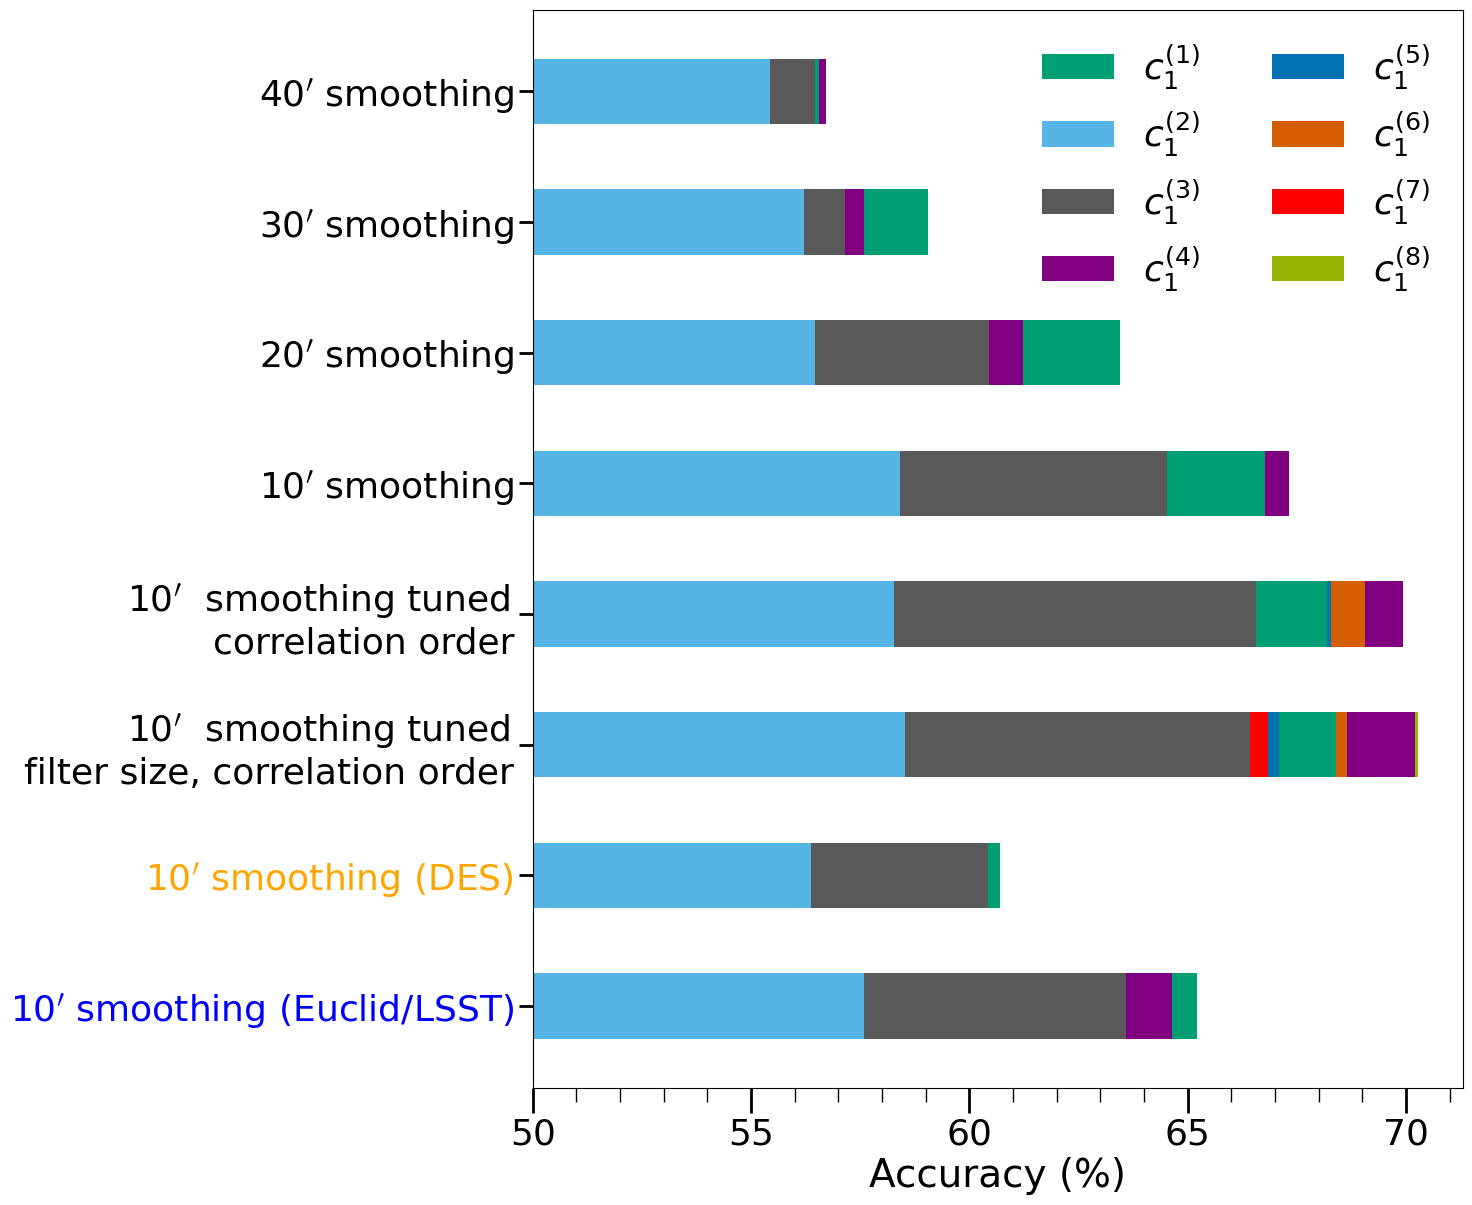

In [40]:
fig, ax = plt.subplots(figsize=(12,14))
test_group = [r'$10^{\prime}$ '+'smoothing (Euclid/LSST)', r'$10^{\prime}$ '+'smoothing (DES)', r'$10^{\prime}$ '+' smoothing tuned \nfilter size, correlation order', r'$10^{\prime}$ '+' smoothing tuned \ncorrelation order', r'$10^{\prime}$ '+'smoothing', r'$20^{\prime}$ '+'smoothing', r'$30^{\prime}$ '+'smoothing', r'$40^{\prime}$ '+'smoothing']
start = np.array([50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0])
c2 = np.array([7.59, 6.38, 8.53, 8.28, 8.41, 6.47, 6.21, 5.43]) 
c3 = np.array([6.00, 4.05, 7.90, 8.28, 6.12, 3.97, 0.95, 1.03])

test_group1 = [r'$10^{\prime}$ '+'smoothing', r'$40^{\prime}$ '+'smoothing']
start1 = np.array([50.0, 50.0])
c1_1 = np.array([2.24, 0.09])
c2_1 = np.array([8.41, 5.43])
c3_1 = np.array([6.12, 1.03])
c4_1 = np.array([0.54, 0.17])

test_group2 = [r'$10^{\prime}$ '+'smoothing (Euclid/LSST)', r'$10^{\prime}$ '+'smoothing (DES)', r'$20^{\prime}$ '+'smoothing', r'$30^{\prime}$ '+'smoothing']
start2 = np.array([50.0, 50.0, 50.0, 50.0])
c1_2 = np.array([0.58, 0.27, 2.24, 1.47])
c2_2 = np.array([7.59, 6.38, 6.47, 6.21])
c3_2 = np.array([6.00, 4.05, 3.97, 0.95])
c4_2 = np.array([1.05, 0.0, 0.78, 0.43])

test_group3 = [r'$10^{\prime}$ '+' smoothing tuned \nfilter size, correlation order']
start3 = np.array([50])
c1_3 = np.array([1.29])
c2_3 = np.array([8.53])
c3_3 = np.array([7.90])
c4_3 = np.array([1.55])
c5_3 = np.array([0.26])
c6_3 = np.array([0.26])
c7_3 = np.array([0.41])
c8_3 = np.array([0.086])

test_group4 = [r'$10^{\prime}$ '+' smoothing tuned \ncorrelation order']
start4 = np.array([50])
c1_4 = np.array([1.64])
c2_4 = np.array([8.28])
c3_4 = np.array([8.28])
c4_4 = np.array([0.86])
c5_4 = np.array([0.086])
c6_4 = np.array([0.78])
#c7_4 = np.array([0.26])
#c8_4 = np.array([0.34])

height = np.array([0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5])
height1 = np.array([0.5, 0.5])
height2 = np.array([0.5, 0.5, 0.5, 0.5])
height3 = np.array([0.5])
height4 = np.array([0.5])

b2 = ax.barh(test_group, c2, left=start, color="#56b5e5", height=height)
b3 = ax.barh(test_group, c3, left=c2+start, color="#595959", height=height)
b1_1 = ax.barh(test_group1, c1_1, left=c2_1+c3_1+start1, color="#009f73", height=height1)
b4_1 = ax.barh(test_group1, c4_1, left=c2_1+c3_1+c1_1+start1, color='#810081', height=height1)
b4_2 = ax.barh(test_group2, c4_2, left=c2_2+c3_2+start2, color='#810081', height=height2)
b1_2 = ax.barh(test_group2, c1_2, left=c2_2+c3_2+c4_2+start2, color='#009f73', height=height2)

b7_3 = ax.barh(test_group3, c7_3, left=c2_3+c3_3+start3, color='red', height=height3) 
b5_3 = ax.barh(test_group3, c5_3, left=c2_3+c3_3+c7_3+start3, color='#0072b1', height=height3) 
b1_3 = ax.barh(test_group3, c1_3, left=c2_3+c3_3+c7_3+c5_3+start3, color='#009f73', height=height3) 
b6_3 = ax.barh(test_group3, c6_3, left=c2_3+c3_3+c7_3+c5_3+c1_3+start3, color='#d55e00', height=height3) 
b4_3 = ax.barh(test_group3, c4_3, left=c2_3+c3_3+c7_3+c5_3+c1_3+c6_3+start3, color='#810081', height=height3) 
b8_3 = ax.barh(test_group3, c8_3, left=c2_3+c3_3+c7_3+c5_3+c1_3+c6_3+c4_3+start3, color='#96b403', height=height3) 

b1_4 = ax.barh(test_group4, c1_4, left=c2_4+c3_4+start4, color="#009f73", height=height4)
b5_4 = ax.barh(test_group4, c5_4, left=c1_4+c2_4+c3_4+start4, color='#0072b1', height=height4)
b6_4 = ax.barh(test_group4, c6_4, left=c5_4+c1_4+c2_4+c3_4+start4, color='#d55e00', height=height4)
b4_4 = ax.barh(test_group4, c4_4, left=c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='#810081', height=height4)
#b11_4 = plt.barh(test_group4, c7_4, left=c4_4+c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='red', height=height4)
#b12_4 = plt.barh(test_group4, c8_4, left=c7_4+c4_4+c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='#96b403', height=height4)

#plt.legend([b3_1, b1, b2, b4_1, b9_4, b8_4, b11_4, b12_4], [r"$c_1^{(1)}$", r"$c_1^{(2)}$", r"$c_1^{(3)}$", r"$c_1^{(4)}$", r"$c_1^{(5)}$", r"$c_1^{(6)}$", r"$c_1^{(7)}$", r"$c_1^{(8)}$"], loc="upper right", frameon=False, fontsize=20, ncols=2)
ax.legend([b1_1, b2, b3, b4_1, b5_3, b6_3, b7_3, b8_3], [r"$c_1^{(1)}$", r"$c_1^{(2)}$", r"$c_1^{(3)}$", r"$c_1^{(4)}$", r"$c_1^{(5)}$", r"$c_1^{(6)}$", r"$c_1^{(7)}$", r"$c_1^{(8)}$"], loc="upper right", frameon=False, fontsize=26, ncols=2)
ax.minorticks_on()
ax.set_xlabel('Accuracy (%)', fontsize=28)
ax.set_xlim(left=50.0)
ax.get_yticklabels()[0].set_color("blue")
ax.get_yticklabels()[1].set_color("orange")
ax.tick_params(axis='x', which='major', length=18.0, width=2.0, labelsize=26)
ax.tick_params(axis='y', which='major', length=10.0, width=2.0, labelsize=26)
#ax.set_yticks([])
ax.tick_params(axis='x', which='minor', length=10.0, width=1.0)
ax.tick_params(axis='y', which='minor', length=0.0, width=1.0)
#plt.title('Noiseless', fontsize=22.0, pad=12.0)


#plt.show()
plt.savefig('paper_plot/ccnn_on_w0_accuracy.pdf', format='pdf', dpi=300, bbox_inches='tight')
#plt.savefig('paper_plot/ccnn_on_w0_noisy.pdf', format='pdf', dpi=300, bbox_inches='tight')

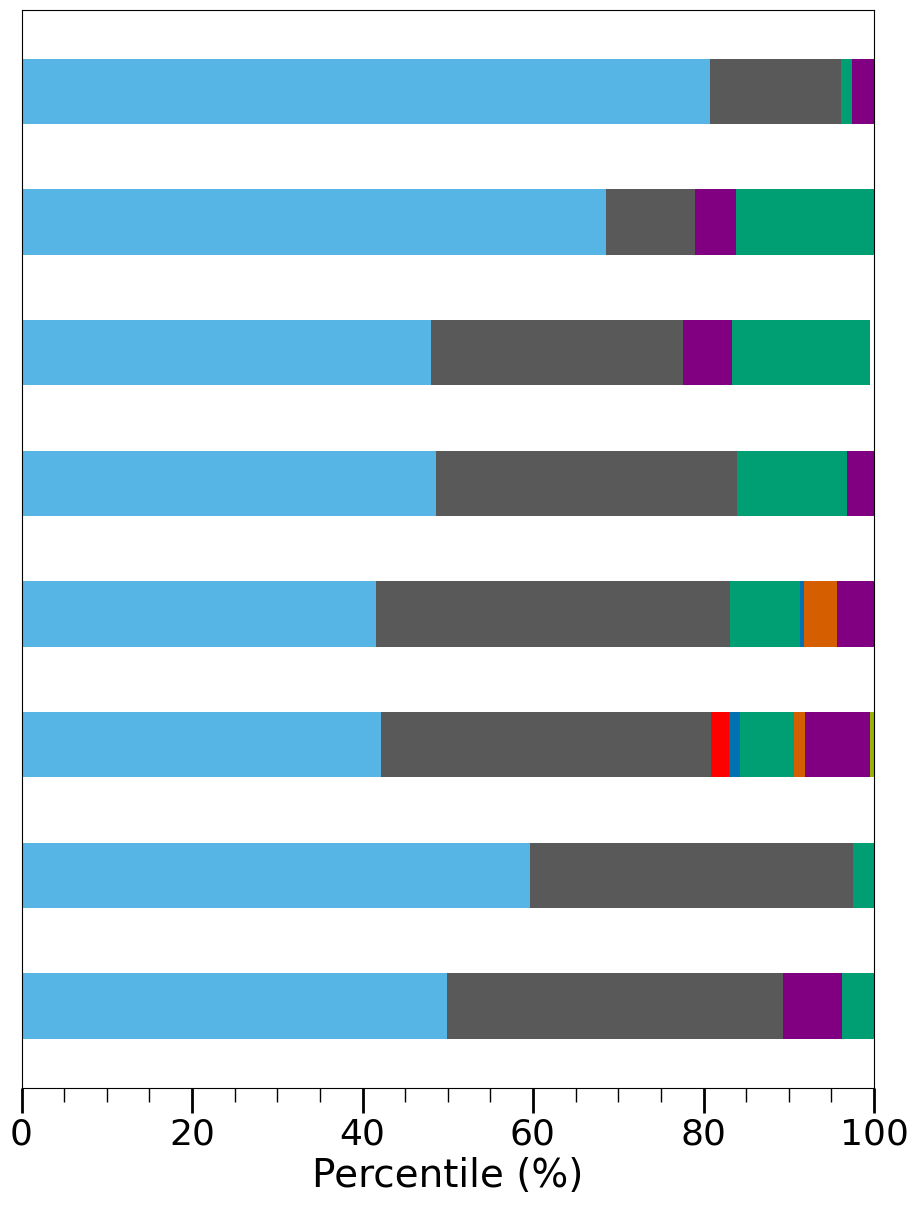

In [44]:
fig, ax = plt.subplots(figsize=(11,14))
test_group = [r'$10^{\prime}$ '+'smoothing (Euclid/LSST)', r'$10^{\prime}$ '+'smoothing (DES)', r'$10^{\prime}$ '+' smoothing and \ntuned filter size, \ncorrelation order', r'$10^{\prime}$ '+' smoothing and \ntuned correlation order', r'$10^{\prime}$ '+'smoothing', r'$20^{\prime}$ '+'smoothing', r'$30^{\prime}$ '+'smoothing', r'$40^{\prime}$ '+'smoothing']
start = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0])
c2 = np.array([49.87, 59.63, 42.17, 41.55, 48.58, 48.09, 68.54, 80.8]) 
c3 = np.array([39.42, 37.85, 38.76, 41.55, 35.36, 29.49, 10.49, 15.33])

test_group1 = [r'$10^{\prime}$ '+'smoothing', r'$40^{\prime}$ '+'smoothing']
start1 = np.array([0.0, 0.0])
c1_1 = np.array([12.94, 1.34])
c2_1 = np.array([48.58, 80.8])
c3_1 = np.array([35.36, 15.33])
c4_1 = np.array([3.12, 2.53])

test_group2 = [r'$10^{\prime}$ '+'smoothing (Euclid/LSST)', r'$10^{\prime}$ '+'smoothing (DES)', r'$20^{\prime}$ '+'smoothing', r'$30^{\prime}$ '+'smoothing']
start2 = np.array([0.0, 0.0, 0.0, 0.0])
c1_2 = np.array([3.81, 2.52, 16.14, 16.23])
c2_2 = np.array([49.87, 59.63, 48.09, 68.54])
c3_2 = np.array([39.42, 37.85, 29.49, 10.49])
c4_2 = np.array([6.90, 0.0, 5.79, 4.75])

test_group3 = [r'$10^{\prime}$ '+' smoothing and \ntuned filter size, \ncorrelation order']
start3 = np.array([0])
c1_3 = np.array([6.38])
c2_3 = np.array([42.17])
c3_3 = np.array([38.76])
c4_3 = np.array([7.66])
c5_3 = np.array([1.29])
c6_3 = np.array([1.29])
c7_3 = np.array([2.03])
c8_3 = np.array([0.43])

test_group4 = [r'$10^{\prime}$ '+' smoothing and \ntuned correlation order']
start4 = np.array([0])
c1_4 = np.array([8.23])
c2_4 = np.array([41.55])
c3_4 = np.array([41.55])
c4_4 = np.array([4.32])
c5_4 = np.array([0.43])
c6_4 = np.array([3.91])
#c7_4 = np.array([0.26])
#c8_4 = np.array([0.34])

height = np.array([0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5])
height1 = np.array([0.5, 0.5])
height2 = np.array([0.5, 0.5, 0.5, 0.5])
height3 = np.array([0.5])
height4 = np.array([0.5])

b1 = ax.barh(test_group, c2, left=start, color="#56b5e5", height=height)
b2 = ax.barh(test_group, c3, left=c2+start, color="#595959", height=height)
b3_1 = ax.barh(test_group1, c1_1, left=c2_1+c3_1+start1, color="#009f73", height=height1)
b4_1 = ax.barh(test_group1, c4_1, left=c2_1+c3_1+c1_1+start1, color='#810081', height=height1)
b3_2 = ax.barh(test_group2, c4_2, left=c2_2+c3_2+start2, color='#810081', height=height2)
b4_2 = ax.barh(test_group2, c1_2, left=c2_2+c3_2+c4_2+start2, color='#009f73', height=height2)

b7_3 = ax.barh(test_group3, c7_3, left=c2_3+c3_3+start3, color='red', height=height3) 
b5_3 = ax.barh(test_group3, c5_3, left=c2_3+c3_3+c7_3+start3, color='#0072b1', height=height3) 
b1_3 = ax.barh(test_group3, c1_3, left=c2_3+c3_3+c7_3+c5_3+start3, color='#009f73', height=height3) 
b6_3 = ax.barh(test_group3, c6_3, left=c2_3+c3_3+c7_3+c5_3+c1_3+start3, color='#d55e00', height=height3) 
b4_3 = ax.barh(test_group3, c4_3, left=c2_3+c3_3+c7_3+c5_3+c1_3+c6_3+start3, color='#810081', height=height3) 
b8_3 = ax.barh(test_group3, c8_3, left=c2_3+c3_3+c7_3+c5_3+c1_3+c6_3+c4_3+start3, color='#96b403', height=height3) 

b7_4 = ax.barh(test_group4, c1_4, left=c2_4+c3_4+start4, color="#009f73", height=height4)
b8_4 = ax.barh(test_group4, c5_4, left=c1_4+c2_4+c3_4+start4, color='#0072b1', height=height4)
b9_4 = ax.barh(test_group4, c6_4, left=c5_4+c1_4+c2_4+c3_4+start4, color='#d55e00', height=height4)
b10_4 = ax.barh(test_group4, c4_4, left=c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='#810081', height=height4)
#b11_4 = plt.barh(test_group4, c7_4, left=c4_4+c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='red', height=height4)
#b12_4 = plt.barh(test_group4, c8_4, left=c7_4+c4_4+c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='#96b403', height=height4)

#plt.legend([b3_1, b1, b2, b4_1, b9_4, b8_4, b11_4, b12_4], [r"$c_1^{(1)}$", r"$c_1^{(2)}$", r"$c_1^{(3)}$", r"$c_1^{(4)}$", r"$c_1^{(5)}$", r"$c_1^{(6)}$", r"$c_1^{(7)}$", r"$c_1^{(8)}$"], loc="upper right", frameon=False, fontsize=20, ncols=2)
#ax.legend([b3_1, b1, b2, b4_1, b8_4, b9_4], [r"$c_1^{(1)}$", r"$c_1^{(2)}$", r"$c_1^{(3)}$", r"$c_1^{(4)}$", r"$c_1^{(5)}$", r"$c_1^{(6)}$"], loc="upper right", frameon=False, fontsize=26, ncols=2)
ax.minorticks_on()
ax.set_xlabel('Percentile (%)', fontsize=28)
ax.set_xlim(left=0.0, right=100.0)
ax.get_yticklabels()[0].set_color("blue")
ax.get_yticklabels()[1].set_color("orange")
ax.tick_params(axis='x', which='major', length=18.0, width=2.0, labelsize=26)
ax.tick_params(axis='y', which='major', length=10.0, width=2.0, labelsize=22)
ax.set_yticks([])
ax.tick_params(axis='x', which='minor', length=10.0, width=1.0)
ax.tick_params(axis='y', which='minor', length=0.0, width=1.0)

#plt.show()
plt.savefig('paper_plot/ccnn_on_w0_percentile.pdf', format='pdf', dpi=300, bbox_inches='tight')

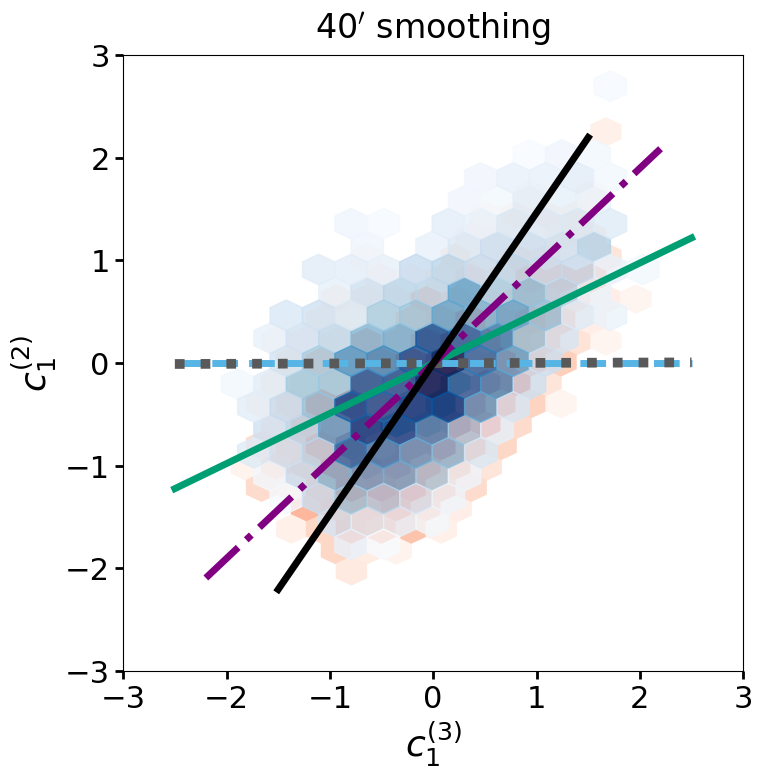

In [23]:
x_decision_1 = β_αs[:, 2][np.nonzero(-β_αs[:, 1])[0][0]]
y_decision_1 = β_αs[:, 1][np.nonzero(-β_αs[:, 1])[0][0]+1]
intercep_decision_1 = β_αs_intercept[np.nonzero(-β_αs[:, 1])[0][0]]
x_1 = np.linspace(-2.5, 2.5, 100)
y_1 = -x_decision_1/y_decision_1*x_1 - intercep_decision_1/y_decision_1

x_decision_2 = β_αs[:, 2][np.nonzero(-β_αs[:, 2])[0][0]]
y_decision_2 = β_αs[:, 1][np.nonzero(-β_αs[:, 2])[0][0]]
intercep_decision_2 = β_αs_intercept[np.nonzero(-β_αs[:, 2])[0][0]]
x_2 = np.linspace(-2.5, 2.5, 100)
y_2 = -x_decision_2/y_decision_2*x_2 - intercep_decision_2/y_decision_2

x_decision_3 = β_αs[:, 2][np.nonzero(-β_αs[:, 0])[0][0]]
y_decision_3 = β_αs[:, 1][np.nonzero(-β_αs[:, 0])[0][0]]
intercep_decision_3 = β_αs_intercept[np.nonzero(-β_αs[:, 0])[0][0]]
x_3 = np.linspace(-2.5, 2.5, 100)
y_3 = -x_decision_3/y_decision_3*x_3 - intercep_decision_3/y_decision_3

x_decision_4 = β_αs[:, 2][np.nonzero(-β_αs[:, 3])[0][0]]
y_decision_4 = β_αs[:, 1][np.nonzero(-β_αs[:, 3])[0][0]]
intercep_decision_4 = β_αs_intercept[np.nonzero(-β_αs[:, 3])[0][0]]
x_4 = np.linspace(-2.2, 2.2, 100)
y_4 = (-x_decision_4/y_decision_4)*x_4 - intercep_decision_4/y_decision_4

x_decision_last = β_αs[:, 2][-1]
y_decision_last = β_αs[:, 1][-1]
intercep_decision_last = β_αs_intercept[-1]
x_last = np.linspace(-1.5, 1.5, 100)
y_last = -x_decision_last/y_decision_last*x_last - intercep_decision_last/y_decision_last

plt.figure(figsize=(8, 8))
hist1 = plt.hexbin(train_cαs_A_norm[:,2], train_cαs_A_norm[:,1], gridsize=30, cmap='Reds', mincnt=10, alpha=1.0)
hist2 = plt.hexbin(train_cαs_B_norm[:,2], train_cαs_B_norm[:,1], gridsize=30, cmap='Blues', mincnt=10, alpha=0.8)
plt.plot(x_3, y_3, linestyle='-', color='#009f73', lw=5.0, label='decision boundary at '+r'$\beta_{1}^{(1)}$'+' activation')
plt.plot(x_1, y_1, linestyle='--', color='#56b5e5', lw=5.0, label='decision boundary at '+r'$\beta_{1}^{(2)}$'+' activation')
plt.plot(x_2, y_2, linestyle='dotted', color='#595959', lw=7.0, label='decision boundary at '+r'$\beta_{1}^{(3)}$'+' activation')
plt.plot(x_4, y_4, linestyle='dashdot', color='#810081', lw=5.0, label='decision boundary at '+r'$\beta_{1}^{(4)}$'+' activation')
plt.plot(x_last, y_last, linestyle='-', color='black', lw=5.0, label='decision boundary at the last '+r'$\lambda$'+' value')
#plt.colorbar(hist1, orientation='vertical', label='Gaussian random field')
#plt.colorbar(hist2, orientation='vertical', label='Log-normal random field')
#tick_font_size = 22
#cbar = plt.colorbar(hist1, orientation='vertical')
#cbar.ax.tick_params(labelsize=tick_font_size)
#cbar.set_label(r'$w_0=-0.95$',size=26, labelpad=0.1)
#cbar1 = plt.colorbar(hist2, orientation='vertical')
#cbar1.ax.tick_params(labelsize=tick_font_size)
#cbar1.set_label(r'$w_0=-1.05$',size=26, labelpad=0.1)

#plt.colorbar(hist1, orientation='vertical', label=r'$\kappa$ '+'only')
#plt.colorbar(hist2, orientation='vertical', label=r'$A_{IA}=0.36$ '+r'$\alpha=1.66$')
plt.xlabel(r'$c^{(3)}_1$', fontsize=26)
plt.ylabel(r'$c^{(2)}_1$', fontsize=26)
plt.xlim([-3.0, 3.0])
plt.ylim([-3.0, 3.0])
plt.tick_params(labelsize=22, length=6.0, width=2.0)
#plt.yticks(color='w')
#plt.legend(fontsize=26, frameon=False, loc='center left', bbox_to_anchor=(1.6, 0.5))
# plt.margins(0.1) # Uncomment this if hex bins are partially outside of plot limits

plt.title(r'$40^{\prime}$'+' smoothing', fontsize=24, pad=12.0)
#plt.title('no smoothing', fontsize=24, pad=12.0)

#plt.show()
plt.savefig('paper_plot/noiseless_w0_40arcmin_smoothing_c2_c3_contour.pdf', format='pdf', dpi=300, bbox_inches='tight')

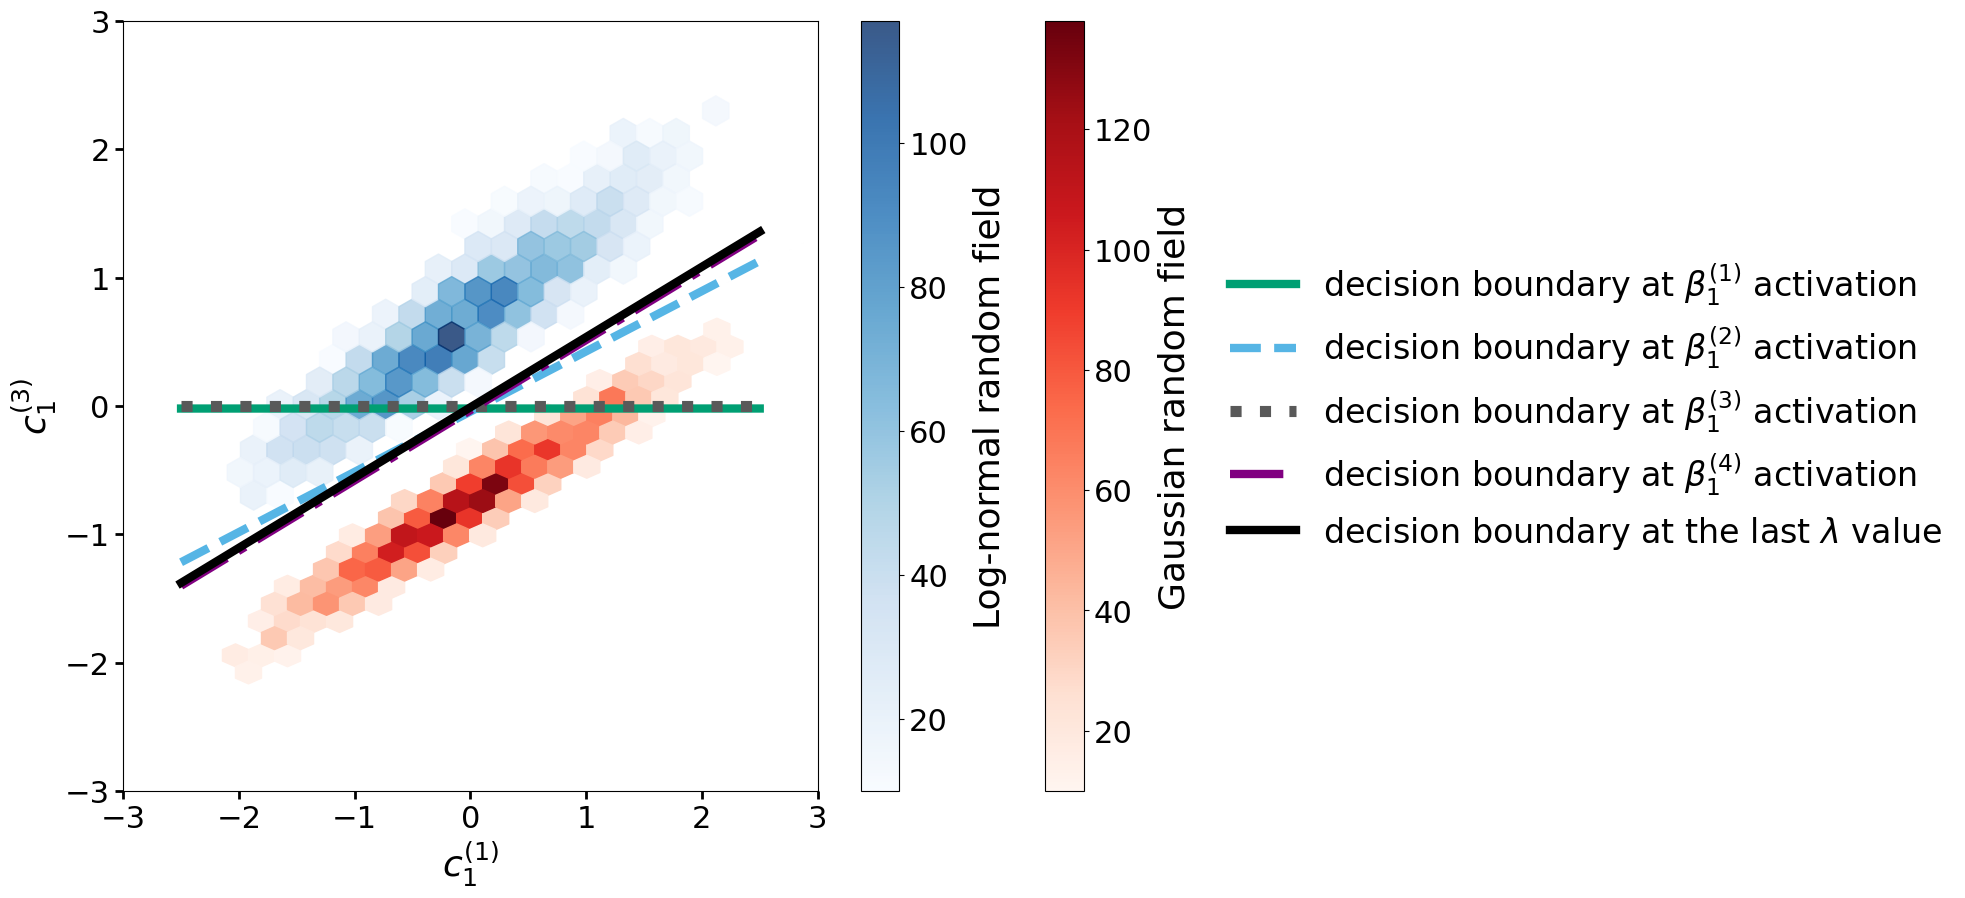

In [22]:
x_decision_1 = β_αs[:, 0][np.nonzero(-β_αs[:, 1])[0][0]]
y_decision_1 = β_αs[:, 2][np.nonzero(-β_αs[:, 1])[0][0]+1]
intercep_decision_1 = β_αs_intercept[np.nonzero(-β_αs[:, 1])[0][0]]
x_1 = np.linspace(-2.5, 2.5, 100)
y_1 = -x_decision_1/y_decision_1*x_1 - intercep_decision_1/y_decision_1

x_decision_2 = β_αs[:, 0][np.nonzero(-β_αs[:, 2])[0][0]]
y_decision_2 = β_αs[:, 2][np.nonzero(-β_αs[:, 2])[0][0]]
intercep_decision_2 = β_αs_intercept[np.nonzero(-β_αs[:, 2])[0][0]]
x_2 = np.linspace(-2.5, 2.5, 100)
y_2 = -x_decision_2/y_decision_2*x_2 - intercep_decision_2/y_decision_2

x_decision_3 = β_αs[:, 0][np.nonzero(-β_αs[:, 0])[0][0]]
y_decision_3 = β_αs[:, 2][np.nonzero(-β_αs[:, 0])[0][0]]
intercep_decision_3 = β_αs_intercept[np.nonzero(-β_αs[:, 0])[0][0]]
x_3 = np.linspace(-2.5, 2.5, 100)
y_3 = -x_decision_3/y_decision_3*x_3 - intercep_decision_3/y_decision_3

x_decision_4 = β_αs[:, 0][np.nonzero(-β_αs[:, 3])[0][0]]
y_decision_4 = β_αs[:, 2][np.nonzero(-β_αs[:, 3])[0][0]]
intercep_decision_4 = β_αs_intercept[np.nonzero(-β_αs[:, 3])[0][0]]
x_4 = np.linspace(-2.5, 2.5, 100)
y_4 = -x_decision_4/y_decision_4*x_4 - intercep_decision_4/y_decision_4

x_decision_last = β_αs[:, 0][-1]
y_decision_last = β_αs[:, 2][-1]
intercep_decision_last = β_αs_intercept[-1]
x_last = np.linspace(-2.5, 2.5, 100)
y_last = -x_decision_last/y_decision_last*x_last - intercep_decision_last/y_decision_last

plt.figure(figsize=(14, 10))
hist1 = plt.hexbin(train_cαs_A_norm[:,0], train_cαs_A_norm[:,2], gridsize=30, cmap='Reds', mincnt=10, alpha=1.0)
hist2 = plt.hexbin(train_cαs_B_norm[:,0], train_cαs_B_norm[:,2], gridsize=30, cmap='Blues', mincnt=10, alpha=0.8)
plt.plot(x_3, y_3, linestyle='-', color='#009f73', lw=6.0, label='decision boundary at '+r'$\beta_{1}^{(1)}$'+' activation')
plt.plot(x_1, y_1, linestyle='--', color='#56b5e5', lw=6.0, label='decision boundary at '+r'$\beta_{1}^{(2)}$'+' activation')
plt.plot(x_2, y_2, linestyle='dotted', color='#595959', lw=8.0, label='decision boundary at '+r'$\beta_{1}^{(3)}$'+' activation')
plt.plot(x_4, y_4, linestyle='dashdot', color='#810081', lw=6.0, label='decision boundary at '+r'$\beta_{1}^{(4)}$'+' activation')
plt.plot(x_last, y_last, linestyle='-', color='black', lw=6.0, label='decision boundary at the last '+r'$\lambda$'+' value')
#plt.colorbar(hist1, orientation='vertical', label='Gaussian random field')
#plt.colorbar(hist2, orientation='vertical', label='Log-normal random field')
tick_font_size = 22
cbar = plt.colorbar(hist1, orientation='vertical')
cbar.ax.tick_params(labelsize=tick_font_size)
cbar.set_label('Gaussian random field',size=26)
cbar1 = plt.colorbar(hist2, orientation='vertical')
cbar1.ax.tick_params(labelsize=tick_font_size)
cbar1.set_label('Log-normal random field',size=26)

#plt.colorbar(hist1, orientation='vertical', label=r'$\kappa$ '+'only')
#plt.colorbar(hist2, orientation='vertical', label=r'$A_{IA}=0.36$ '+r'$\alpha=1.66$')
plt.xlabel(r'$c^{(1)}_1$', fontsize=26)
plt.ylabel(r'$c^{(3)}_1$', fontsize=26)
plt.xlim([-3.0, 3.0])
plt.ylim([-3.0, 3.0])
plt.tick_params(labelsize=22, length=6.0, width=2.0)
#plt.yticks(color='w')
plt.legend(fontsize=24, frameon=False, loc='center left', bbox_to_anchor=(1.55, 0.5))
# plt.margins(0.1) # Uncomment this if hex bins are partially outside of plot limits

#plt.title(r'$10^{\prime}$'+' smoothing', fontsize=24, pad=12.0)
#plt.title('no smoothing', fontsize=24, pad=12.0)

#plt.show()
plt.savefig('paper_plot/grf_lognormal_c1_c3_contour.pdf', format='pdf', dpi=300, bbox_inches='tight')

In [31]:
error_classification_A = []
error_classification_B = []
for i in range(train_cαs_A_norm.shape[0]):
    if (train_cαs_A_norm[i,0] < -x_decision_1/y_decision_1*train_cαs_A_norm[i,2] - intercep_decision_1/y_decision_1):
        error_classification_A.append(1)
        
for i in range(train_cαs_B_norm.shape[0]):
    if (train_cαs_B_norm[i,0] > -x_decision_1/y_decision_1*train_cαs_B_norm[i,2] - intercep_decision_1/y_decision_1):
        error_classification_B.append(1)

In [32]:
1 - (len(error_classification_A)+len(error_classification_B))/(2*train_cαs_A_norm.shape[0])

0.7871934434434434

### Use Chainconsumer to plot the measured correlation features

In [21]:
from chainconsumer import ChainConsumer

In [63]:
random_3d_vec = np.random.uniform(-3.0, 5.0, (10000000, 3))
c1 = (-β_αs_intercept[-1] - β_αs[:,1][-1]*random_3d_vec[:,0] - β_αs[:,2][-1]*random_3d_vec[:,1] - β_αs[:,3][-1]*random_3d_vec[:,2])/β_αs[:,0][-1]
hyperplane = np.concatenate((c1.reshape(-1,1), random_3d_vec), axis=1)

In [20]:
train_cαs_A = np.load('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_gaussian_6300maps_w_model_on_20deg_200pix.npy')
train_cαs_C = np.load('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_gaussian_6300maps_10deg_100pix_w_model_on_20deg_200pix.npy')
train_cαs_E = np.load('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_gaussian_1800maps_40deg_400pix_w_model_on_20deg_200pix.npy')

train_cαs_B = np.load('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_lognormal_6300maps_w_model_on_20deg_200pix.npy')
train_cαs_D = np.load('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_lognormal_6300maps_10deg_100pix_w_model_on_20deg_200pix.npy')
train_cαs_F = np.load('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_lognormal_1800maps_40deg_400pix_w_model_on_20deg_200pix.npy')

In [25]:
#correlation_gaussian_filter = train_cαs_A
#correlation_gaussian_filter_l = train_cαs_B
#correlation_gaussian_filter_s = train_cαs_C
#correlation_lognormal_filter = train_cαs_D
#correlation_lognormal_filter_l = train_cαs_E
#correlation_lognormal_filter_s = train_cαs_F

#correlation_gaussian = train_cαs_A
#correlation_gaussian_s = train_cαs_C[:,1::2]
#correlation_gaussian_l = train_cαs_E[:,1::2]
#correlation_lognormal = train_cαs_B
#correlation_lognormal_s = train_cαs_D
#correlation_lognormal_l = train_cαs_F

correlation_grf_lambda5 = train_cαs_A[:,:3]
correlation_grf_lambda20 = train_cαs_B[:,:3]

#correlation_gaussian = train_cαs_A
#correlation_lognormal = train_cαs_B

#correlation_no_IA = train_cαs_A
#correlation_IA_Aamp = train_cαs_B

In [42]:
label = ['Gaussian random field', 'Gaussian random field larger map', 'Gaussian random field larger filter', 'Gaussian random field smaller filter', 'Log-normal random field', 'Log-normal random field larger map', 'Log-normal random field larger filter', 'Log random field smaller filter', 'Gaussian random field short '+r'$\lambda$', 'smaller Gaussian random field short '+r'$\lambda$', 'Gaussian random field middle '+r'$\lambda$', 'Gaussian random field long '+r'$\lambda$', r'$M_{\nu} = 0.0$ '+'eV', r'$M_{\nu} = 0.1$ '+'eV']

c = ChainConsumer()
#c.add_chain(correlation_gaussian_filter, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Gaussian map filter 31 pixels', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=2.0)
#c.add_chain(correlation_gaussian_filter_l, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Gaussian map filter 51 pixels', shade=True, shade_alpha=0.1, color='r', linestyle='--', linewidth=1.0, kde=2.0)
#c.add_chain(correlation_gaussian_filter_s, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Gaussian map filter 11 pixels', shade=True, shade_alpha=0.1, color='blue', linestyle='--', linewidth=1.0, kde=2.0)


c.add_chain(correlation_grf_lambda5, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$"], name='$\ell=5.0$', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=2.0)
c.add_chain(correlation_grf_lambda20, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$"], name='$\ell=20.0$', shade=True, shade_alpha=0.1, color='blue', linestyle='--', linewidth=1.0, kde=2.0)
c.add_marker(np.array([0.0, 0.199, 0.0]), parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$"], marker_style="*", marker_size=100, color="red", name='theory prediction '+'$\ell=5.0$')
c.add_marker(np.array([0.0, 1.049, 0.0]), parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$"], marker_style="*", marker_size=100, color="orange", name='theory prediction '+'$\ell=20.0$')
#c.add_chain(correlation_lambda1, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Log-normal map with initial '+r'$\lambda$', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=2.0)
#c.add_chain(correlation_lambda2, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Log-normal map with modified '+r'$\lambda$', shade=True, shade_alpha=0.1, color='r', linestyle='--', linewidth=1.0, kde=2.0)

#c.add_chain(correlation_no_IA, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name=r'$\kappa$ '+'only', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=2.0)
#c.add_chain(correlation_IA_Aamp, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name=r'$\kappa$ + '+'IA with '+r'$A_{IA}=0.36$, '+r'$\alpha=1.66$', shade=True, shade_alpha=0.1, color='r', linestyle='--', linewidth=1.0, kde=2.0)

#c.add_chain(correlation_lognormal, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Log-normal map size 20 degree', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=2.0)
#c.add_chain(correlation_lognormal_s, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Log-normal map size 10 degree', shade=True, shade_alpha=0.1, color='r', linestyle='--', linewidth=1.0, kde=2.0)
#c.add_chain(correlation_lognormal_l, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Log-normal map size 40 degree', shade=True, shade_alpha=0.1, color='blue', linestyle='--', linewidth=1.0, kde=2.0)

#c.add_chain(correlation_gaussian, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Gaussian random fields', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=2.0)
#c.add_chain(correlation_lognormal, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Log-normal random fields', shade=True, shade_alpha=0.1, color='r', linestyle='--', linewidth=1.0, kde=2.0)
#c.add_marker(np.array([0.0, 2.414e-4, 0.0, 1.315e-08]), parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], marker_style="*", marker_size=80, color="orange", name='theory prediction for Gaussian')
#c.add_marker(np.array([0.0, 2.414e-4, 8.078e-07, 1.613e-08]), parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], marker_style="*", marker_size=80, color="blue", name='theory prediction for Log-normal')
#c.add_chain(correlation_s, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name=label[2], shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(correlation_s1, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name=label[3], shade=True, shade_alpha=0.1, color='purple', linestyle='--', linewidth=1.5, kde=False)
#c.add_chain(correlation_m, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name=label[4], shade=True, shade_alpha=0.1, color='b', linestyle='--', linewidth=1.0, kde=False)
#c.add_chain(correlation_l, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name=label[5], shade=True, shade_alpha=0.1, color='r', linestyle='--', linewidth=1.0, kde=False)
#c.add_chain(hyperplane, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='decision hyperplane', shade=True, shade_alpha=0.1, color='black', linestyle='--', linewidth=2.0, kde=False)
#c.configure_truth(linestyle='dotted', linewidth=0.5)
c.configure(usetex=False, serif=False, label_font_size=20.0, tick_font_size=20.0, max_ticks=4, summary=False, spacing=2.0, legend_kwargs={'fontsize':20})

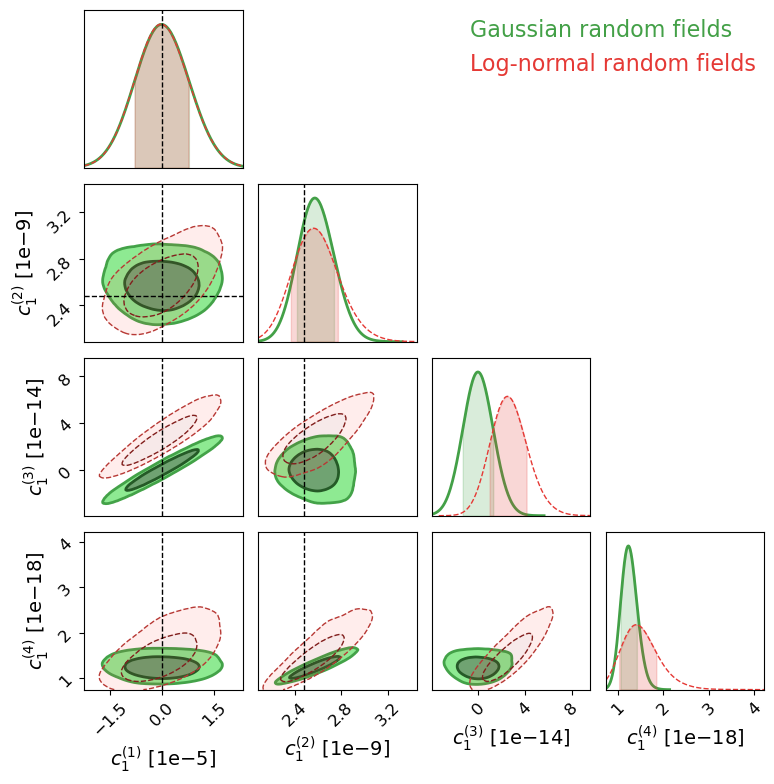

In [175]:
#extent = [(-1.0, 1.0), (min(correlation_s[:,1]), 0.45), (-0.2, 0.2), (min(correlation_s[:,3]), 0.045)]
#extent = [(-3.5e-5, 3.5e-5), (min(correlation_lognormal[:,1]), 4e-9), (min(correlation_lognormal[:,2]), 1.5e-13), (min(correlation_lognormal[:,3]), 1.5e-17)]
#fig = c.plotter.plot(figsize=(8, 8), legend=True, truth=[0.0, 5.083619078207578e-07, 6.324138410600967e-11, 2.5302002985655507e-14])
fig = c.plotter.plot(figsize=(8, 8), legend=True, truth=[0.0, 2.4795401943391353e-09, 6.324138410600967e-11, 2.5302002985655507e-14])

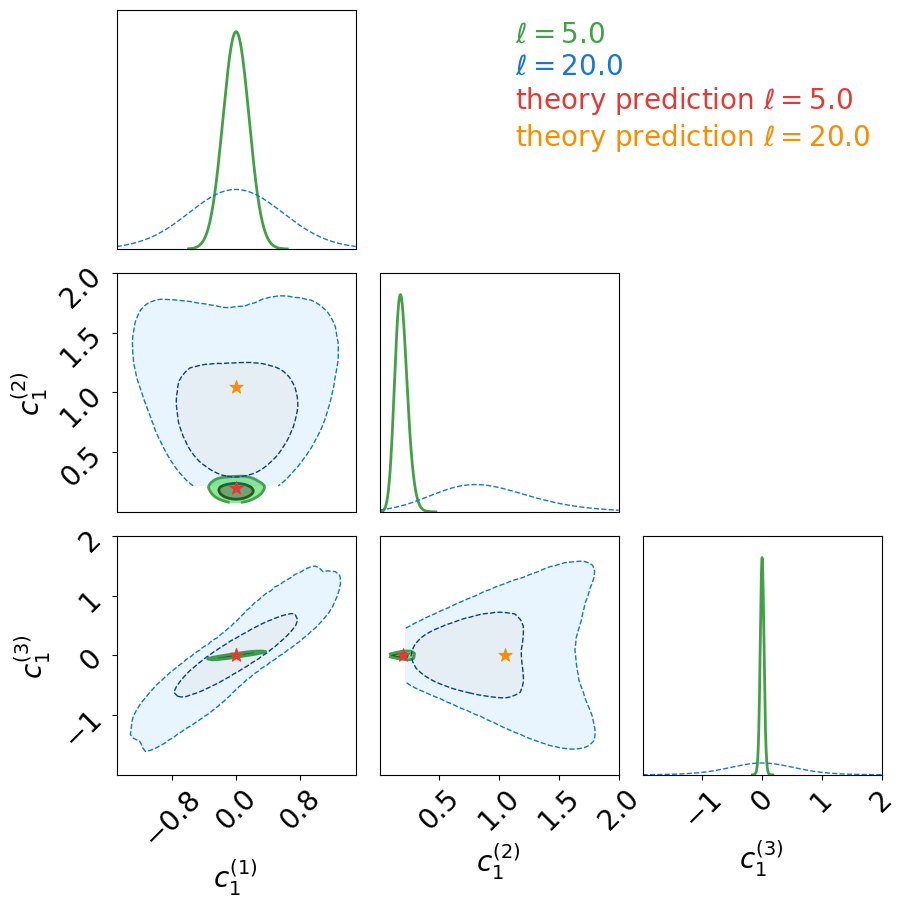

In [44]:
extent = [(-1.5, 1.5), (0, 2.0), (-2.0, 2.0)]
#extent = [(-6e-3, 6e-3), (1.8e-4, 3.2e-4), (-1.5e-6, 2.5e-6), [1e-8, 4e-8]]
fig = c.plotter.plot(figsize=(9, 9), legend=True, extents=extent, filename='paper_plot/corner_plots_grf_lognormal_up_to_c4_test.png')